## To configure the Github repository with the colab notebook here.

In [1]:

import subprocess
from pathlib import Path
from google.colab import userdata

GITHUB_USERNAME = "Priyasahaana"
GITHUB_EMAIL = "2026aj05309@wilp.bits-pilani.ac.in"
REPO_NAME = "2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer"
REPO_URL = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME

def run_git(args, input_text=None, check=True):
    return subprocess.run(
        ["git"] + args,
        input=input_text,
        text=True,
        capture_output=True,
        check=check
    )

print("DNN ASSIGNMENT 2 - GITHUB CONNECTION")

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
if not GITHUB_TOKEN:
    raise ValueError("GITHUB_TOKEN not found in Colab Secrets.")

run_git(["config", "--global", "--replace-all", "credential.helper", "cache --timeout=3600"])

credential_text = (
    "protocol=https\n"
    "host=github.com\n"
    f"username={GITHUB_USERNAME}\n"
    f"password={GITHUB_TOKEN}\n\n"
)

run_git(["credential", "reject"], input_text=credential_text, check=False)
run_git(["credential", "approve"], input_text=credential_text)

del GITHUB_TOKEN, credential_text

if REPO_DIR.exists():
    if not (REPO_DIR / ".git").exists():
        raise RuntimeError("Repository folder exists but is not a Git repository.")
else:
    run_git(["clone", REPO_URL, str(REPO_DIR)])

remotes = run_git(["-C", str(REPO_DIR), "remote"]).stdout.split()

if "origin" not in remotes:
    run_git(["-C", str(REPO_DIR), "remote", "add", "origin", REPO_URL])
else:
    run_git(["-C", str(REPO_DIR), "remote", "set-url", "origin", REPO_URL])

run_git(["-C", str(REPO_DIR), "config", "user.name", GITHUB_USERNAME])
run_git(["-C", str(REPO_DIR), "config", "user.email", GITHUB_EMAIL])
run_git(["-C", str(REPO_DIR), "branch", "-M", "main"])

status = run_git(["-C", str(REPO_DIR), "status", "--porcelain"]).stdout.strip()

if status:
    raise RuntimeError(
        "Uncommitted changes found. Commit or safely handle them before syncing."
    )

run_git(["-C", str(REPO_DIR), "fetch", "origin"])

remote_branch = run_git(
    ["-C", str(REPO_DIR), "show-ref", "--verify", "--quiet", "refs/remotes/origin/main"],
    check=False
)

if remote_branch.returncode == 0:
    run_git(["-C", str(REPO_DIR), "pull", "--rebase", "origin", "main"])

PROJECT_DIR = REPO_DIR / "2026AJ05309_DNN_Assignment2"
PROBLEM1_DIR = PROJECT_DIR / "problem1"
P1_FIGURES_DIR = PROBLEM1_DIR / "figures"
MODEL_DIR = PROBLEM1_DIR / "models"
ADDING_MODEL_DIR = PROBLEM1_DIR / "adding_models"
ABLATION_DIR = PROBLEM1_DIR / "hidden_size_ablation"
FORGET_DIR = PROBLEM1_DIR / "forget_gate_ablation"

for folder in [
    PROBLEM1_DIR,
    P1_FIGURES_DIR,
    MODEL_DIR,
    ADDING_MODEL_DIR,
    ABLATION_DIR,
    FORGET_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("\nGITHUB CONNECTION COMPLETED")
print("Repository:", REPO_URL)
print("Local directory:", REPO_DIR)
print("Branch:", run_git(["-C", str(REPO_DIR), "branch", "--show-current"]).stdout.strip())

print("\nGIT STATUS")
print(run_git(["-C", str(REPO_DIR), "status", "--short", "--branch"]).stdout.strip())

print("\nPROBLEM 1 FOLDERS")
print("Problem 1:", PROBLEM1_DIR)
print("Figures:", P1_FIGURES_DIR)
print("Models:", MODEL_DIR)
print("Adding models:", ADDING_MODEL_DIR)
print("Hidden-size ablation:", ABLATION_DIR)
print("Forget-gate ablation:", FORGET_DIR)

print("\nLATEST COMMIT")
print(run_git(["-C", str(REPO_DIR), "log", "-1", "--oneline"]).stdout.strip())


DNN ASSIGNMENT 2 - GITHUB CONNECTION

GITHUB CONNECTION COMPLETED
Repository: https://github.com/Priyasahaana/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer.git
Local directory: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer
Branch: main

GIT STATUS
## main...origin/main

PROBLEM 1 FOLDERS
Problem 1: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1
Figures: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures
Models: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/models
Adding models: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/adding_models
Hidden-size ablation: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/hidden_size_ablation
Forget-gate ablation: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transf

## For needed Python and library versions

In [2]:
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
Scikit-learn: 1.6.1

GPU available: True
GPU name: Tesla T4


## Step 1 — Create the assignment folders and set reproducibility

In [3]:

import random
import os
from pathlib import Path

SEED = 42
TEST_SIZE = 0.20
BATCH_SIZE = 64
HIDDEN_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_DIR = REPO_DIR / "2026AJ05309_DNN_Assignment2"
PROBLEM1_DIR = PROJECT_DIR / "problem1"
PROBLEM2_DIR = PROJECT_DIR / "problem2"
DATA_DIR = PROJECT_DIR / "data"

P1_FIGURES_DIR = PROBLEM1_DIR / "figures"
P2_FIGURES_DIR = PROBLEM2_DIR / "figures"

for folder in [PROBLEM1_DIR, PROBLEM2_DIR, DATA_DIR, P1_FIGURES_DIR, P2_FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Assignment folders created.")
print("Project directory:", PROJECT_DIR)
print("Problem 1 directory:", PROBLEM1_DIR)
print("Problem 2 directory:", PROBLEM2_DIR)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Random seed:", SEED)


Assignment folders created.
Project directory: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2
Problem 1 directory: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1
Problem 2 directory: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem2
GPU: Tesla T4
Random seed: 42


## Step 2 — Downloading and loading the UCI HAR dataset

In [4]:
import urllib.request
import zipfile

HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_ZIP = Path("/content/UCI_HAR_Dataset.zip")
HAR_EXTRACT_DIR = Path("/content/UCI_HAR_Dataset")

HAR_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not HAR_ZIP.exists():
    print("Downloading UCI HAR dataset...")
    urllib.request.urlretrieve(HAR_URL, HAR_ZIP)

NESTED_ZIP = HAR_EXTRACT_DIR / "UCI HAR Dataset.zip"

if not NESTED_ZIP.exists():
    with zipfile.ZipFile(HAR_ZIP, "r") as zip_file:
        zip_file.extractall(HAR_EXTRACT_DIR)

HAR_DIR = HAR_EXTRACT_DIR / "UCI HAR Dataset"
SIGNALS_DIR = HAR_DIR / "train" / "Inertial Signals"

if not SIGNALS_DIR.exists():
    with zipfile.ZipFile(NESTED_ZIP, "r") as zip_file:
        zip_file.extractall(HAR_EXTRACT_DIR)

assert SIGNALS_DIR.exists(), "Inertial Signals folder was not found."

feature_names = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_har_split(split):
    split_dir = HAR_DIR / split
    signals_dir = split_dir / "Inertial Signals"

    signals = []

    for feature in feature_names:
        file_path = signals_dir / f"{feature}_{split}.txt"
        assert file_path.exists(), f"Missing file: {file_path}"
        signal = np.loadtxt(file_path, dtype=np.float32)
        signals.append(signal)

    X = np.stack(signals, axis=2)

    y = np.loadtxt(split_dir / f"y_{split}.txt", dtype=np.int64)
    subjects = np.loadtxt(split_dir / f"subject_{split}.txt", dtype=np.int64)

    return X, y, subjects

X_train_raw, y_train, train_subjects_all = load_har_split("train")
X_test_raw, y_test, test_subjects = load_har_split("test")
y_test_original = y_test.copy()

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

train_subject_ids = np.unique(train_subjects_all)
test_subject_ids = np.unique(test_subjects)

print("UCI HAR dataset loaded.")
print("Training data shape:", X_train_raw.shape)
print("Training labels shape:", y_train.shape)
print("Training subjects:", len(train_subject_ids))
print("Test data shape:", X_test_raw.shape)
print("Test labels shape:", y_test.shape)
print("Test subjects:", len(test_subject_ids))
print("Number of input channels:", len(feature_names))
print("Number of activity classes:", len(activity_names))

assert X_train_raw.shape == (7352, 128, 9)
assert X_test_raw.shape == (2947, 128, 9)
assert len(train_subject_ids) == 21
assert len(test_subject_ids) == 9
assert set(np.unique(y_train)) == {1, 2, 3, 4, 5, 6}
assert set(np.unique(y_test)) == {1, 2, 3, 4, 5, 6}
assert len(set(train_subject_ids).intersection(set(test_subject_ids))) == 0

print("Dataset shape and subject split checks passed.")


UCI HAR dataset loaded.
Training data shape: (7352, 128, 9)
Training labels shape: (7352,)
Training subjects: 21
Test data shape: (2947, 128, 9)
Test labels shape: (2947,)
Test subjects: 9
Number of input channels: 9
Number of activity classes: 6
Dataset shape and subject split checks passed.


## Step 3 — Create three subject-wise validation splits

In [5]:

VALIDATION_SEEDS = [13, 309, 2004]

validation_splits = {}

for seed in VALIDATION_SEEDS:
    rng = np.random.default_rng(seed)
    validation_subject_ids = rng.choice(train_subject_ids, 4, replace=False)
    training_subject_ids = np.setdiff1d(train_subject_ids, validation_subject_ids)

    train_indices = np.where(np.isin(train_subjects_all, training_subject_ids))[0]
    val_indices = np.where(np.isin(train_subjects_all, validation_subject_ids))[0]

    X_train = X_train_raw[train_indices]
    y_train_split = y_train[train_indices]

    X_val = X_train_raw[val_indices]
    y_val = y_train[val_indices]

    assert len(training_subject_ids) == 17
    assert len(validation_subject_ids) == 4
    assert len(set(training_subject_ids) & set(validation_subject_ids)) == 0
    assert len(set(training_subject_ids) & set(test_subject_ids)) == 0
    assert len(set(validation_subject_ids) & set(test_subject_ids)) == 0

    validation_splits[seed] = {
        "X_train": X_train,
        "y_train": y_train_split,
        "X_val": X_val,
        "y_val": y_val,
        "train_subjects": training_subject_ids,
        "val_subjects": validation_subject_ids
    }

    print("Seed:", seed)
    print("Training subjects:", len(training_subject_ids))
    print("Validation subjects:", len(validation_subject_ids))
    print("Training samples:", len(X_train))
    print("Validation samples:", len(X_val))
    print("Training and validation subjects overlap:",
          len(set(training_subject_ids) & set(validation_subject_ids)))
    print()

print("All three validation splits created successfully.")


Seed: 13
Training subjects: 17
Validation subjects: 4
Training samples: 5858
Validation samples: 1494
Training and validation subjects overlap: 0

Seed: 309
Training subjects: 17
Validation subjects: 4
Training samples: 5988
Validation samples: 1364
Training and validation subjects overlap: 0

Seed: 2004
Training subjects: 17
Validation subjects: 4
Training samples: 5880
Validation samples: 1472
Training and validation subjects overlap: 0

All three validation splits created successfully.


## Step 4 — Normalisation and class balance

Seed: 13
Training mean: [ 0.0000 -0.0000  0.0000  0.0000  0.0000  0.0000  0.0008  0.0000 -0.0000]
Training standard deviation: [1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 0.9998 1.0001 1.0000]
Training shape: (5858, 128, 9)
Validation shape: (1494, 128, 9)
Test shape: (2947, 128, 9)

Seed: 309
Training mean: [-0.0000 -0.0000  0.0000  0.0000 -0.0000 -0.0000  0.0003  0.0000  0.0000]
Training standard deviation: [1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 1.0002 1.0000 1.0000]
Training shape: (5988, 128, 9)
Validation shape: (1364, 128, 9)
Test shape: (2947, 128, 9)

Seed: 2004
Training mean: [ 0.0000 -0.0000  0.0000  0.0000 -0.0000  0.0000 -0.0000 -0.0000  0.0000]
Training standard deviation: [1.0000 1.0000 1.0000 1.0000 1.0000 1.0000 0.9997 0.9998 1.0000]
Training shape: (5880, 128, 9)
Validation shape: (1472, 128, 9)
Test shape: (2947, 128, 9)

Normalisation checks passed.


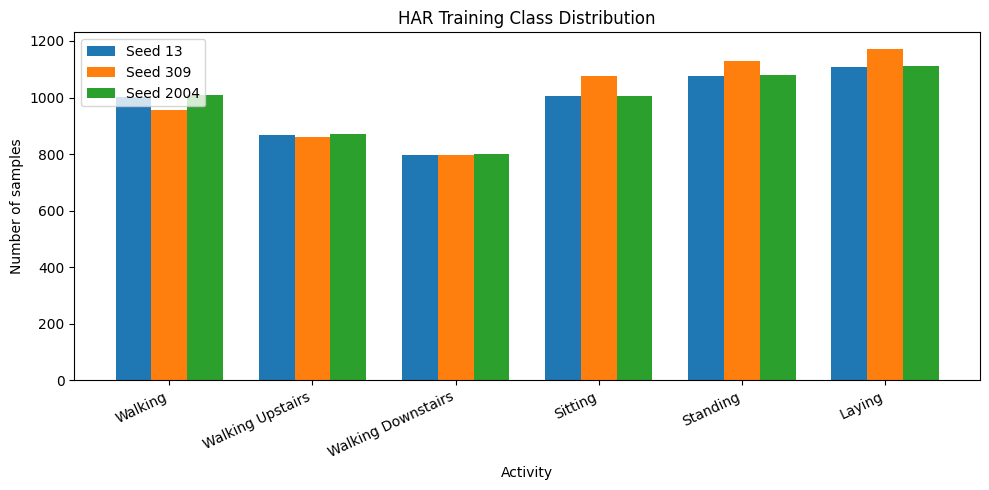

Class balance figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/class_balance.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=4, suppress=True, floatmode="fixed")

for seed, split in validation_splits.items():
    X_train = split["X_train"]
    X_val = split["X_val"]

    channel_mean = X_train.mean(axis=(0, 1))
    channel_std = X_train.std(axis=(0, 1))
    channel_std[channel_std == 0] = 1.0

    X_train_norm = (X_train - channel_mean) / channel_std
    X_val_norm = (X_val - channel_mean) / channel_std
    X_test_norm = (X_test_raw - channel_mean) / channel_std

    split["mean"] = channel_mean
    split["std"] = channel_std
    split["X_train_norm"] = X_train_norm
    split["X_val_norm"] = X_val_norm
    split["X_test_norm"] = X_test_norm

    assert X_train_norm.shape == X_train.shape
    assert X_val_norm.shape == X_val.shape
    assert X_test_norm.shape == X_test_raw.shape
    assert np.all(np.isfinite(X_train_norm))
    assert np.all(np.isfinite(X_val_norm))
    assert np.all(np.isfinite(X_test_norm))

    train_mean = X_train_norm.mean(axis=(0, 1))
    train_std = X_train_norm.std(axis=(0, 1))

    assert np.allclose(train_mean, 0, atol=0.01)
    assert np.allclose(train_std, 1, atol=0.01)

    print("Seed:", seed)
    print("Training mean:", train_mean)
    print("Training standard deviation:", train_std)
    print("Training shape:", X_train_norm.shape)
    print("Validation shape:", X_val_norm.shape)
    print("Test shape:", X_test_norm.shape)
    print()

print("Normalisation checks passed.")

class_counts = {}

for seed, split in validation_splits.items():
    class_counts[seed] = np.bincount(
        split["y_train"], minlength=7
    )[1:7]

x = np.arange(len(activity_names))
width = 0.25

plt.figure(figsize=(10, 5))

for i, seed in enumerate(VALIDATION_SEEDS):
    plt.bar(
        x + (i - 1) * width,
        class_counts[seed],
        width,
        label=f"Seed {seed}"
    )

plt.xticks(x, activity_names, rotation=25, ha="right")
plt.xlabel("Activity")
plt.ylabel("Number of samples")
plt.title("HAR Training Class Distribution")
plt.legend()
plt.tight_layout()

class_balance_path = P1_FIGURES_DIR / "class_balance.png"
plt.savefig(class_balance_path, dpi=300, bbox_inches="tight")
plt.show()

print("Class balance figure saved:", class_balance_path)

## Step 5 — Implement custom RNN, LSTM and GRU cells

In [7]:

import torch
import torch.nn as nn

class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.weight_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(hidden_size))

    def forward(self, x, h):
        h_new = torch.tanh(
            x @ self.weight_ih.T + self.bias_ih
            + h @ self.weight_hh.T + self.bias_hh
        )
        return h_new


class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.weight_ih = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(4 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(4 * hidden_size))

    def forward(self, x, state):
        h, c = state

        gates = (
            x @ self.weight_ih.T + self.bias_ih
            + h @ self.weight_hh.T + self.bias_hh
        )

        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)

        return h_new, c_new


class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.weight_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(3 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(3 * hidden_size))

    def forward(self, x, h):
        input_gates = x @ self.weight_ih.T + self.bias_ih
        hidden_gates = h @ self.weight_hh.T + self.bias_hh

        i_r, i_z, i_n = input_gates.chunk(3, dim=1)
        h_r, h_z, h_n = hidden_gates.chunk(3, dim=1)

        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)

        h_new = (1 - z) * n + z * h

        return h_new


print("Custom RNN, LSTM and GRU cell classes defined.")

Custom RNN, LSTM and GRU cell classes defined.


### Step 5A — Verify custom cells against PyTorch

In [8]:
torch.manual_seed(42)

input_size = 9
hidden_size = 64
batch_size = 4
sequence_length = 10

X = torch.randn(batch_size, sequence_length, input_size)

h0 = torch.randn(1, batch_size, hidden_size)
c0 = torch.randn(1, batch_size, hidden_size)

# RNN verification
reference_rnn = nn.RNN(
    input_size, hidden_size, batch_first=True
)

custom_rnn = MyRNNCell(input_size, hidden_size)

with torch.no_grad():
    custom_rnn.weight_ih.copy_(reference_rnn.weight_ih_l0)
    custom_rnn.weight_hh.copy_(reference_rnn.weight_hh_l0)
    custom_rnn.bias_ih.copy_(reference_rnn.bias_ih_l0)
    custom_rnn.bias_hh.copy_(reference_rnn.bias_hh_l0)

custom_outputs = []
h = h0.squeeze(0)

for t in range(sequence_length):
    h = custom_rnn(X[:, t, :], h)
    custom_outputs.append(h)

custom_outputs = torch.stack(custom_outputs, dim=1)
reference_outputs, _ = reference_rnn(X, h0)

rnn_difference = torch.max(
    torch.abs(custom_outputs - reference_outputs)
).item()

assert rnn_difference < 1e-5
print("RNN maximum difference:", rnn_difference)


# LSTM verification
reference_lstm = nn.LSTM(
    input_size, hidden_size, batch_first=True
)

custom_lstm = MyLSTMCell(input_size, hidden_size)

with torch.no_grad():
    custom_lstm.weight_ih.copy_(reference_lstm.weight_ih_l0)
    custom_lstm.weight_hh.copy_(reference_lstm.weight_hh_l0)
    custom_lstm.bias_ih.copy_(reference_lstm.bias_ih_l0)
    custom_lstm.bias_hh.copy_(reference_lstm.bias_hh_l0)

custom_outputs = []
h = h0.squeeze(0)
c = c0.squeeze(0)

for t in range(sequence_length):
    h, c = custom_lstm(X[:, t, :], (h, c))
    custom_outputs.append(h)

custom_outputs = torch.stack(custom_outputs, dim=1)
reference_outputs, (reference_h, reference_c) = reference_lstm(
    X, (h0, c0)
)

lstm_difference = torch.max(
    torch.abs(custom_outputs - reference_outputs)
).item()

assert lstm_difference < 1e-5
print("LSTM maximum difference:", lstm_difference)


# GRU verification
reference_gru = nn.GRU(
    input_size, hidden_size, batch_first=True
)

custom_gru = MyGRUCell(input_size, hidden_size)

with torch.no_grad():
    custom_gru.weight_ih.copy_(reference_gru.weight_ih_l0)
    custom_gru.weight_hh.copy_(reference_gru.weight_hh_l0)
    custom_gru.bias_ih.copy_(reference_gru.bias_ih_l0)
    custom_gru.bias_hh.copy_(reference_gru.bias_hh_l0)

custom_outputs = []
h = h0.squeeze(0)

for t in range(sequence_length):
    h = custom_gru(X[:, t, :], h)
    custom_outputs.append(h)

custom_outputs = torch.stack(custom_outputs, dim=1)
reference_outputs, _ = reference_gru(X, h0)

gru_difference = torch.max(
    torch.abs(custom_outputs - reference_outputs)
).item()

assert gru_difference < 1e-5
print("GRU maximum difference:", gru_difference)

print("\nAll custom cell verification tests passed.")


RNN maximum difference: 1.1920928955078125e-07
LSTM maximum difference: 8.940696716308594e-08
GRU maximum difference: 1.7881393432617188e-07

All custom cell verification tests passed.


### Step 5B — Check parameter counts

In [9]:

custom_cells = {
    "RNN": MyRNNCell(input_size, hidden_size),
    "LSTM": MyLSTMCell(input_size, hidden_size),
    "GRU": MyGRUCell(input_size, hidden_size)
}

for name, model in custom_cells.items():
    parameter_count = sum(
        parameter.numel() for parameter in model.parameters()
    )
    print(f"{name} custom cell parameters: {parameter_count:,}")


RNN custom cell parameters: 4,800
LSTM custom cell parameters: 19,200
GRU custom cell parameters: 14,400


## Step 6 — Build the HAR classification models

### Step 6A — Define the classifier and training functions

In [10]:
import copy
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class HARSequenceClassifier(nn.Module):
    def __init__(self, model_type, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()

        self.model_type = model_type

        if model_type == "RNN":
            self.recurrent = nn.RNN(
                input_size, hidden_size, batch_first=True
            )
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size, hidden_size, batch_first=True
            )
        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                input_size, hidden_size, batch_first=True
            )
        else:
            raise ValueError("Unknown model type.")

        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        if self.model_type == "LSTM":
            _, (hidden, _) = self.recurrent(x)
        else:
            _, hidden = self.recurrent(x)

        last_hidden = hidden[-1]
        return self.classifier(last_hidden)


def evaluate_classifier(model, X, y):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        predictions = torch.argmax(logits, dim=1)

    true_labels = y.cpu().numpy()
    predicted_labels = predictions.cpu().numpy()

    accuracy = accuracy_score(true_labels, predicted_labels)
    macro_f1 = f1_score(
        true_labels, predicted_labels, average="macro"
    )

    return accuracy, macro_f1


print("HAR classifier and evaluation functions defined.")
print("Device:", DEVICE)


HAR classifier and evaluation functions defined.
Device: cuda


### Step 6B — Train and evaluate all three models

In [11]:

MODEL_DIR = PROBLEM1_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_TYPES = ["RNN", "LSTM", "GRU"]
har_results = []

for model_type in MODEL_TYPES:
    for seed in VALIDATION_SEEDS:
        print(f"\nTraining {model_type} | Seed {seed}")

        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        split = validation_splits[seed]

        X_train_tensor = torch.tensor(
            split["X_train_norm"], dtype=torch.float32, device=DEVICE
        )
        y_train_tensor = torch.tensor(
            split["y_train"] - 1, dtype=torch.long, device=DEVICE
        )
        X_val_tensor = torch.tensor(
            split["X_val_norm"], dtype=torch.float32, device=DEVICE
        )
        y_val_tensor = torch.tensor(
            split["y_val"] - 1, dtype=torch.long, device=DEVICE
        )
        X_test_tensor = torch.tensor(
            split["X_test_norm"], dtype=torch.float32, device=DEVICE
        )
        y_test_tensor = torch.tensor(
            y_test - 1, dtype=torch.long, device=DEVICE
        )

        model = HARSequenceClassifier(
            model_type=model_type,
            input_size=9,
            hidden_size=HIDDEN_SIZE,
            num_classes=6
        ).to(DEVICE)

        parameter_count = sum(
            parameter.numel() for parameter in model.parameters()
        )

        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(
            model.parameters(), lr=LEARNING_RATE
        )

        best_val_f1 = -1.0
        best_state = None
        epoch_times = []

        for epoch in range(EPOCHS):
            model.train()
            epoch_start = time.perf_counter()

            permutation = torch.randperm(
                len(X_train_tensor), device=DEVICE
            )

            total_loss = 0.0

            for start in range(0, len(permutation), BATCH_SIZE):
                indices = permutation[start:start + BATCH_SIZE]

                batch_X = X_train_tensor[indices]
                batch_y = y_train_tensor[indices]

                optimizer.zero_grad()
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(indices)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            epoch_time = time.perf_counter() - epoch_start
            epoch_times.append(epoch_time)

            val_accuracy, val_f1 = evaluate_classifier(
                model, X_val_tensor, y_val_tensor
            )

            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_state = copy.deepcopy(model.state_dict())

            if (epoch + 1) % 5 == 0:
                average_loss = total_loss / len(X_train_tensor)
                print(
                    f"Epoch {epoch + 1}/{EPOCHS} | "
                    f"Loss: {average_loss:.4f} | "
                    f"Validation accuracy: {val_accuracy:.4f} | "
                    f"Validation macro-F1: {val_f1:.4f}"
                )

        model.load_state_dict(best_state)

        test_accuracy, test_f1 = evaluate_classifier(
            model, X_test_tensor, y_test_tensor
        )

        seconds_per_epoch = float(np.mean(epoch_times))

        checkpoint_path = MODEL_DIR / (
            f"{model_type.lower()}_seed_{seed}.pt"
        )
        torch.save(model.state_dict(), checkpoint_path)

        run_result = {
            "model": model_type,
            "seed": seed,
            "test_accuracy": test_accuracy,
            "macro_f1": test_f1,
            "best_validation_macro_f1": best_val_f1,
            "parameters": parameter_count,
            "seconds_per_epoch": seconds_per_epoch,
            "checkpoint": str(checkpoint_path)
        }

        har_results.append(run_result)

        print("Best validation macro-F1:", round(best_val_f1, 4))
        print("Test accuracy:", round(test_accuracy, 4))
        print("Test macro-F1:", round(test_f1, 4))
        print("Parameters:", f"{parameter_count:,}")
        print("Seconds per epoch:", round(seconds_per_epoch, 4))
        print("Saved:", checkpoint_path)

print("\nAll HAR classification runs completed.")



Training RNN | Seed 13
Epoch 5/30 | Loss: 0.7660 | Validation accuracy: 0.7028 | Validation macro-F1: 0.6602
Epoch 10/30 | Loss: 0.6011 | Validation accuracy: 0.7523 | Validation macro-F1: 0.7170
Epoch 15/30 | Loss: 0.4332 | Validation accuracy: 0.8340 | Validation macro-F1: 0.8229
Epoch 20/30 | Loss: 0.5850 | Validation accuracy: 0.8367 | Validation macro-F1: 0.8154
Epoch 25/30 | Loss: 0.2964 | Validation accuracy: 0.8976 | Validation macro-F1: 0.8914
Epoch 30/30 | Loss: 0.3424 | Validation accuracy: 0.8715 | Validation macro-F1: 0.8630
Best validation macro-F1: 0.9009
Test accuracy: 0.8161
Test macro-F1: 0.8159
Parameters: 5,190
Seconds per epoch: 0.2405
Saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/models/rnn_seed_13.pt

Training RNN | Seed 309
Epoch 5/30 | Loss: 1.3450 | Validation accuracy: 0.5601 | Validation macro-F1: 0.4871
Epoch 10/30 | Loss: 0.8329 | Validation accuracy: 0.6642 | Validation macro-F1: 0.6249
Epoch 15

### Step 6C — Create the comparison table

In [12]:
har_results_df = pd.DataFrame(har_results)

har_summary = har_results_df.groupby("model").agg(
    accuracy_mean=("test_accuracy", "mean"),
    accuracy_std=("test_accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    parameters=("parameters", "first"),
    seconds_per_epoch=("seconds_per_epoch", "mean")
).reset_index()

print("HAR Classification Results — Mean and Sample Standard Deviation")
display(har_summary.round(4))

results_path = PROBLEM1_DIR / "har_classification_results.csv"
har_results_df.to_csv(results_path, index=False)

print("Individual run results saved:", results_path)


HAR Classification Results — Mean and Sample Standard Deviation


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,seconds_per_epoch
0,GRU,0.8963,0.0087,0.8970,0.0093,14790,0.2168
1,LSTM,0.8949,0.0061,0.8952,0.0068,19590,0.2431
2,RNN,0.7853,0.0554,0.7831,0.0597,5190,0.2183


Individual run results saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/har_classification_results.csv


### Step 6D — Generate the confusion matrix



RNN MODEL — BEST CHECKPOINT
Selected seed: 13
Validation macro-F1: 0.9009
Test accuracy: 0.8161
Test macro-F1: 0.8159
Trainable parameters: 5190

Confusion Matrix:
[[435  40  21   0   0   0]
 [147 307  15   1   1   0]
 [ 23   1 396   0   0   0]
 [  1  25   0 396  69   0]
 [  3  65   0 104 360   0]
 [  0  26   0   0   0 511]]

Classification Report:
                    precision    recall  f1-score   support

           Walking     0.7143    0.8770    0.7873       496
  Walking Upstairs     0.6616    0.6518    0.6567       471
Walking Downstairs     0.9167    0.9429    0.9296       420
           Sitting     0.7904    0.8065    0.7984       491
          Standing     0.8372    0.6767    0.7484       532
            Laying     1.0000    0.9516    0.9752       537

          accuracy                         0.8161      2947
         macro avg     0.8200    0.8177    0.8159      2947
      weighted avg     0.8217    0.8161    0.8158      2947



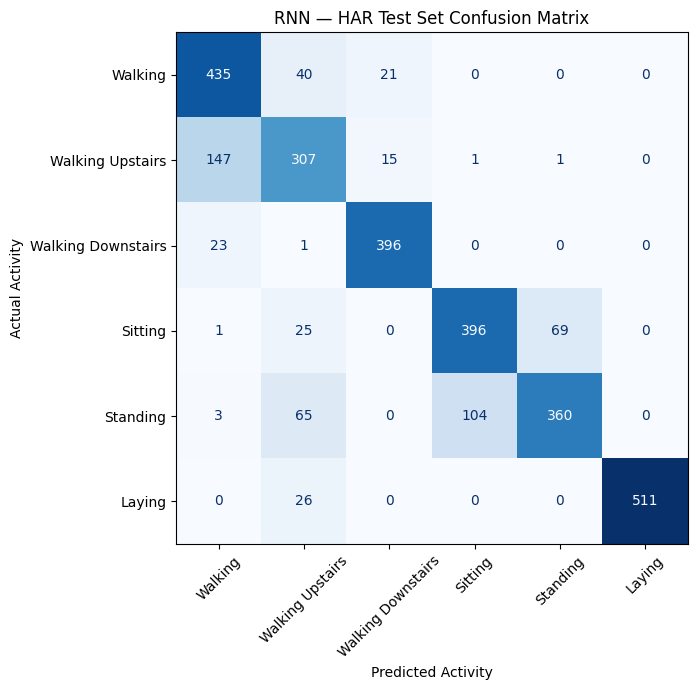

Figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/rnn_har_confusion_matrix.png


LSTM MODEL — BEST CHECKPOINT
Selected seed: 309
Validation macro-F1: 0.9669
Test accuracy: 0.8935
Test macro-F1: 0.8935
Trainable parameters: 19590

Confusion Matrix:
[[475  11  10   0   0   0]
 [  9 441  21   0   0   0]
 [ 10  23 387   0   0   0]
 [  4   5   2 364 116   0]
 [  2   1   0  70 459   0]
 [  0  27   0   3   0 507]]

Classification Report:
                    precision    recall  f1-score   support

           Walking     0.9500    0.9577    0.9538       496
  Walking Upstairs     0.8681    0.9363    0.9009       471
Walking Downstairs     0.9214    0.9214    0.9214       420
           Sitting     0.8330    0.7413    0.7845       491
          Standing     0.7983    0.8628    0.8293       532
            Laying     1.0000    0.9441    0.9713       537

          accuracy                         0.8935      2947
         mac

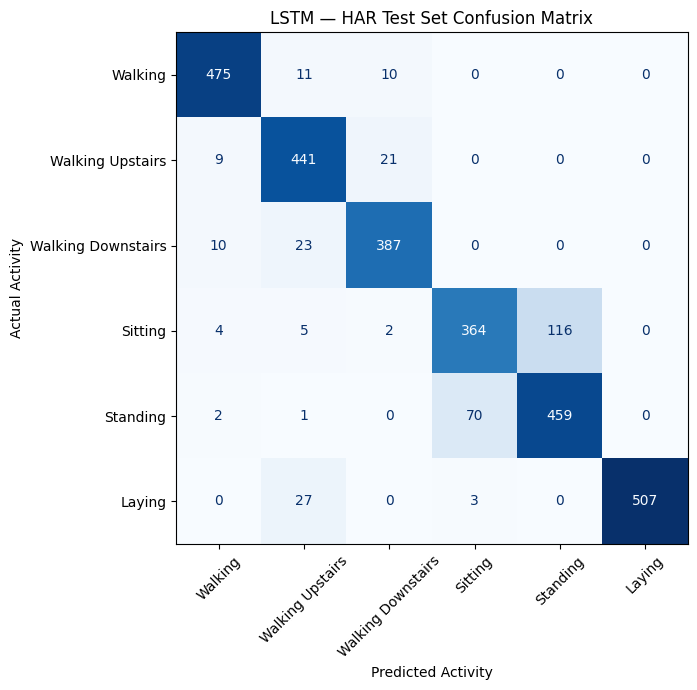

Figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/lstm_har_confusion_matrix.png


GRU MODEL — BEST CHECKPOINT
Selected seed: 309
Validation macro-F1: 0.9782
Test accuracy: 0.8975
Test macro-F1: 0.8985
Trainable parameters: 14790

Confusion Matrix:
[[466  20  10   0   0   0]
 [  9 461   1   0   0   0]
 [ 27   5 388   0   0   0]
 [  0  24   0 386  81   0]
 [  0   0   0  98 434   0]
 [  0  27   0   0   0 510]]

Classification Report:
                    precision    recall  f1-score   support

           Walking     0.9283    0.9395    0.9339       496
  Walking Upstairs     0.8585    0.9788    0.9147       471
Walking Downstairs     0.9724    0.9238    0.9475       420
           Sitting     0.7975    0.7862    0.7918       491
          Standing     0.8427    0.8158    0.8290       532
            Laying     1.0000    0.9497    0.9742       537

          accuracy                         0.8975      2947
         mac

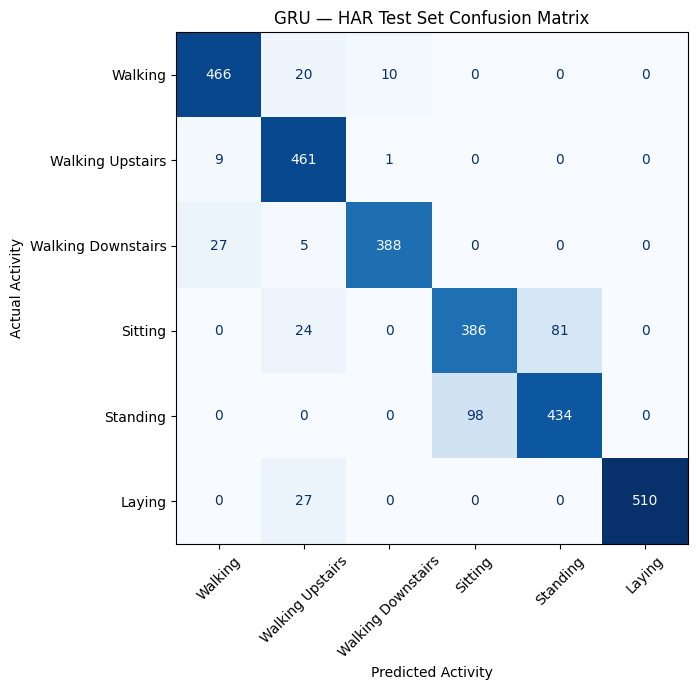

Figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/gru_har_confusion_matrix.png

BEST CHECKPOINT COMPARISON


,model,seed,validation_macro_f1,test_accuracy,test_macro_f1,parameters
0,RNN,13,0.9009,0.8161,0.8159,5190
1,LSTM,309,0.9669,0.8935,0.8935,19590
2,GRU,309,0.9782,0.8975,0.8985,14790



Best model selected using validation macro-F1: GRU


In [13]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)
import matplotlib.pyplot as plt
import numpy as np
import torch

best_checkpoints = {
    "RNN": {"seed": 13, "validation_f1": 0.9009},
    "LSTM": {"seed": 309, "validation_f1": 0.9669},
    "GRU": {"seed": 309, "validation_f1": 0.9782}
}

model_parameters = {
    "RNN": 5190,
    "LSTM": 19590,
    "GRU": 14790
}

model_results = []

y_true = y_test - 1

for model_type, details in best_checkpoints.items():
    seed = details["seed"]
    checkpoint_path = MODEL_DIR / f"{model_type.lower()}_seed_{seed}.pt"

    split = validation_splits[seed]

    X_test_tensor = torch.tensor(
        split["X_test_norm"],
        dtype=torch.float32,
        device=DEVICE
    )

    model = HARSequenceClassifier(
        model_type=model_type,
        input_size=9,
        hidden_size=HIDDEN_SIZE,
        num_classes=6
    ).to(DEVICE)

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )
    )

    model.eval()

    with torch.no_grad():
        outputs = model(X_test_tensor)
        predictions = torch.argmax(outputs, dim=1).cpu().numpy()

    cm = confusion_matrix(y_true, predictions, labels=np.arange(6))
    accuracy = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    model_results.append({
        "model": model_type,
        "seed": seed,
        "validation_macro_f1": details["validation_f1"],
        "test_accuracy": accuracy,
        "test_macro_f1": macro_f1,
        "parameters": model_parameters[model_type]
    })

    print("\n")
    print(f"{model_type} MODEL — BEST CHECKPOINT")
    print("Selected seed:", seed)
    print("Validation macro-F1:", details["validation_f1"])
    print("Test accuracy:", round(accuracy, 4))
    print("Test macro-F1:", round(macro_f1, 4))
    print("Trainable parameters:", model_parameters[model_type])

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            predictions,
            labels=np.arange(6),
            target_names=activity_names,
            digits=4,
            zero_division=0
        )
    )

    fig, ax = plt.subplots(figsize=(9, 7))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=activity_names
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=45,
        colorbar=False
    )

    ax.set_title(f"{model_type} — HAR Test Set Confusion Matrix")
    ax.set_xlabel("Predicted Activity")
    ax.set_ylabel("Actual Activity")

    plt.tight_layout()

    figure_path = (
        P1_FIGURES_DIR /
        f"{model_type.lower()}_har_confusion_matrix.png"
    )

    plt.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Figure saved:", figure_path)

results_comparison = pd.DataFrame(model_results)

print("\nBEST CHECKPOINT COMPARISON")
display(results_comparison.round(4))

best_model = max(
    best_checkpoints,
    key=lambda name: best_checkpoints[name]["validation_f1"]
)

print("\nBest model selected using validation macro-F1:", best_model)

## Step 7 — Adding Problem dataset generation

### Step 7A — Define the Adding Problem generator

In [14]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = (
        x[np.arange(n), i1, 0]
        + x[np.arange(n), i2, 0]
    )

    return x, y.astype(np.float32)


print("Adding Problem generator defined.")

Adding Problem generator defined.


### Step 7B — Generate datasets and run validation checks

In [15]:
SEQUENCE_LENGTHS = [50, 100, 200, 400]

ADDING_TRAIN_SIZE = 10000
ADDING_VAL_SIZE = 1000
ADDING_TEST_SIZE = 1000

adding_datasets = {}

for T in SEQUENCE_LENGTHS:
    X_train_add, y_train_add = make_adding(
        ADDING_TRAIN_SIZE, T, seed=0
    )

    X_val_add, y_val_add = make_adding(
        ADDING_VAL_SIZE, T, seed=1
    )

    X_test_add, y_test_add = make_adding(
        ADDING_TEST_SIZE, T, seed=2
    )

    adding_datasets[T] = {
        "X_train": X_train_add,
        "y_train": y_train_add,
        "X_val": X_val_add,
        "y_val": y_val_add,
        "X_test": X_test_add,
        "y_test": y_test_add
    }

    for X, y, expected_n in [
        (X_train_add, y_train_add, ADDING_TRAIN_SIZE),
        (X_val_add, y_val_add, ADDING_VAL_SIZE),
        (X_test_add, y_test_add, ADDING_TEST_SIZE)
    ]:
        assert X.shape == (expected_n, T, 2)
        assert y.shape == (expected_n,)
        assert np.all(np.isfinite(X))
        assert np.all(np.isfinite(y))

        markers = X[:, :, 1]

        assert np.all(markers.sum(axis=1) == 2)
        assert np.all(markers[:, :T // 2].sum(axis=1) == 1)
        assert np.all(markers[:, T // 2:].sum(axis=1) == 1)

        calculated_targets = (
            X[:, :, 0] * markers
        ).sum(axis=1)

        assert np.allclose(y, calculated_targets, atol=1e-6)

    baseline_prediction = np.mean(y_train_add)
    baseline_mse = np.mean(
        (y_test_add - baseline_prediction) ** 2
    )

    print(f"\nSequence length: {T}")
    print("Training shape:", X_train_add.shape)
    print("Validation shape:", X_val_add.shape)
    print("Test shape:", X_test_add.shape)
    print("Training target mean:", round(float(np.mean(y_train_add)), 4))
    print("Constant-prediction test MSE:", round(float(baseline_mse), 4))

print("\nAll Adding Problem dataset checks passed.")


Sequence length: 50
Training shape: (10000, 50, 2)
Validation shape: (1000, 50, 2)
Test shape: (1000, 50, 2)
Training target mean: 1.0047
Constant-prediction test MSE: 0.1755

Sequence length: 100
Training shape: (10000, 100, 2)
Validation shape: (1000, 100, 2)
Test shape: (1000, 100, 2)
Training target mean: 0.9975
Constant-prediction test MSE: 0.1697

Sequence length: 200
Training shape: (10000, 200, 2)
Validation shape: (1000, 200, 2)
Test shape: (1000, 200, 2)
Training target mean: 0.9951
Constant-prediction test MSE: 0.1681

Sequence length: 400
Training shape: (10000, 400, 2)
Validation shape: (1000, 400, 2)
Test shape: (1000, 400, 2)
Training target mean: 1.0116
Constant-prediction test MSE: 0.1529

All Adding Problem dataset checks passed.


### Step 7C — Train RNN, LSTM and GRU on the Adding Problem

In [16]:
import copy
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ADDING_SEEDS = [13, 309, 2004]
ADDING_EPOCHS = 10
ADDING_BATCH_SIZE = 64
ADDING_HIDDEN_SIZE = 64
ADDING_LR = 0.001

class AddingModel(nn.Module):
    def __init__(self, model_type, input_size=2, hidden_size=64):
        super().__init__()
        self.model_type = model_type

        if model_type == "RNN":
            self.recurrent = nn.RNN(
                input_size, hidden_size, batch_first=True
            )
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size, hidden_size, batch_first=True
            )
        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                input_size, hidden_size, batch_first=True
            )
        else:
            raise ValueError("Unknown model type")

        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        if self.model_type == "LSTM":
            _, (hidden, _) = self.recurrent(x)
        else:
            _, hidden = self.recurrent(x)

        return self.output_layer(hidden[-1]).squeeze(1)


def evaluate_adding(model, X, y):
    model.eval()
    with torch.no_grad():
        predictions = model(X)
        mse = torch.mean((predictions - y) ** 2).item()
    return mse


adding_results = []
adding_histories = {}

ADDING_MODEL_DIR = PROBLEM1_DIR / "adding_models"
ADDING_MODEL_DIR.mkdir(parents=True, exist_ok=True)

for T in SEQUENCE_LENGTHS:
    data = adding_datasets[T]

    X_train = torch.tensor(
        data["X_train"], dtype=torch.float32, device=DEVICE
    )
    y_train = torch.tensor(
        data["y_train"], dtype=torch.float32, device=DEVICE
    )
    X_val = torch.tensor(
        data["X_val"], dtype=torch.float32, device=DEVICE
    )
    y_val = torch.tensor(
        data["y_val"], dtype=torch.float32, device=DEVICE
    )
    X_test = torch.tensor(
        data["X_test"], dtype=torch.float32, device=DEVICE
    )
    y_test_add = torch.tensor(
        data["y_test"], dtype=torch.float32, device=DEVICE
    )

    for model_type in ["RNN", "LSTM", "GRU"]:
        for seed in ADDING_SEEDS:
            print(f"\nTraining {model_type}, T={T}, seed={seed}")

            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)

            model = AddingModel(
                model_type, 2, ADDING_HIDDEN_SIZE
            ).to(DEVICE)

            optimizer = torch.optim.Adam(
                model.parameters(), lr=ADDING_LR
            )
            criterion = nn.MSELoss()

            best_val_mse = float("inf")
            best_state = None
            train_losses = []
            val_losses = []
            epoch_times = []

            for epoch in range(ADDING_EPOCHS):
                model.train()
                start_time = time.perf_counter()

                permutation = torch.randperm(
                    len(X_train), device=DEVICE
                )
                total_loss = 0.0

                for start in range(
                    0, len(permutation), ADDING_BATCH_SIZE
                ):
                    indices = permutation[
                        start:start + ADDING_BATCH_SIZE
                    ]

                    batch_X = X_train[indices]
                    batch_y = y_train[indices]

                    optimizer.zero_grad()
                    predictions = model(batch_X)
                    loss = criterion(predictions, batch_y)
                    loss.backward()
                    optimizer.step()

                    total_loss += loss.item() * len(indices)

                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()

                epoch_times.append(
                    time.perf_counter() - start_time
                )

                train_mse = total_loss / len(X_train)
                val_mse = evaluate_adding(
                    model, X_val, y_val
                )

                train_losses.append(train_mse)
                val_losses.append(val_mse)

                if val_mse < best_val_mse:
                    best_val_mse = val_mse
                    best_state = copy.deepcopy(
                        model.state_dict()
                    )

                if (epoch + 1) % 5 == 0:
                    print(
                        f"Epoch {epoch + 1}/{ADDING_EPOCHS} | "
                        f"Train MSE: {train_mse:.5f} | "
                        f"Validation MSE: {val_mse:.5f}"
                    )

            model.load_state_dict(best_state)
            test_mse = evaluate_adding(
                model, X_test, y_test_add
            )

            params = sum(
                p.numel() for p in model.parameters()
            )

            checkpoint = (
                ADDING_MODEL_DIR /
                f"{model_type.lower()}_T{T}_seed{seed}.pt"
            )
            torch.save(model.state_dict(), checkpoint)

            adding_results.append({
                "model": model_type,
                "sequence_length": T,
                "seed": seed,
                "best_validation_mse": best_val_mse,
                "test_mse": test_mse,
                "solved": test_mse < 0.05,
                "parameters": params,
                "seconds_per_epoch": np.mean(epoch_times)
            })

            if T == 200:
                adding_histories[(model_type, seed)] = {
                    "train": train_losses,
                    "validation": val_losses
                }

            print("Best validation MSE:", round(best_val_mse, 5))
            print("Test MSE:", round(test_mse, 5))
            print("Solved:", test_mse < 0.05)
            print("Saved:", checkpoint)

adding_results_df = pd.DataFrame(adding_results)

adding_results_path = (
    PROBLEM1_DIR / "adding_problem_results.csv"
)
adding_results_df.to_csv(adding_results_path, index=False)

print("\nADDING PROBLEM RESULTS")
display(adding_results_df.round(5))

print("\nResults saved:", adding_results_path)



Training RNN, T=50, seed=13
Epoch 5/10 | Train MSE: 0.16690 | Validation MSE: 0.16594
Epoch 10/10 | Train MSE: 0.16635 | Validation MSE: 0.16708
Best validation MSE: 0.16571
Test MSE: 0.17487
Solved: False
Saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/adding_models/rnn_T50_seed13.pt

Training RNN, T=50, seed=309
Epoch 5/10 | Train MSE: 0.16748 | Validation MSE: 0.16604
Epoch 10/10 | Train MSE: 0.16662 | Validation MSE: 0.16583
Best validation MSE: 0.16583
Test MSE: 0.1744
Solved: False
Saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/adding_models/rnn_T50_seed309.pt

Training RNN, T=50, seed=2004
Epoch 5/10 | Train MSE: 0.16636 | Validation MSE: 0.16605
Epoch 10/10 | Train MSE: 0.16802 | Validation MSE: 0.16606
Best validation MSE: 0.16605
Test MSE: 0.17531
Solved: False
Saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/pro

,model,sequence_length,seed,best_validation_mse,test_mse,solved,parameters,seconds_per_epoch
0,RNN,50,13,0.16571,0.17487,False,4417,0.36861
1,RNN,50,309,0.16583,0.17440,False,4417,0.30544
2,RNN,50,2004,0.16605,0.17531,False,4417,0.30636
3,LSTM,50,13,0.16479,0.17406,False,17473,0.34289
4,LSTM,50,309,0.16479,0.17376,False,17473,0.40344
5,LSTM,50,2004,0.16473,0.17315,False,17473,0.34591
6,GRU,50,13,0.00390,0.00443,True,13121,0.33942
7,GRU,50,309,0.00318,0.00402,True,13121,0.36727
8,GRU,50,2004,0.00436,0.00520,True,13121,0.34285
9,RNN,100,13,0.16037,0.17046,False,4417,0.30230



Results saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/adding_problem_results.csv


### Step 7D — Summarize Adding Problem Results and Generate Plots

ADDING PROBLEM SUMMARY


,model,sequence_length,mean_test_mse,std_test_mse,solved_count,mean_seconds_per_epoch,parameters
0,GRU,50,0.00455,0.00060,3,0.34984,13121
1,GRU,100,0.00606,0.00081,3,0.34709,13121
2,GRU,200,0.04977,0.05339,2,0.35204,13121
3,GRU,400,0.15291,0.00051,0,0.43966,13121
4,LSTM,50,0.17366,0.00046,0,0.36408,17473
5,LSTM,100,0.16978,0.00025,0,0.35178,17473
6,LSTM,200,0.16829,0.00009,0,0.37061,17473
7,LSTM,400,0.15382,0.00038,0,0.40656,17473
8,RNN,50,0.17486,0.00045,0,0.32680,4417
9,RNN,100,0.17007,0.00040,0,0.31655,4417


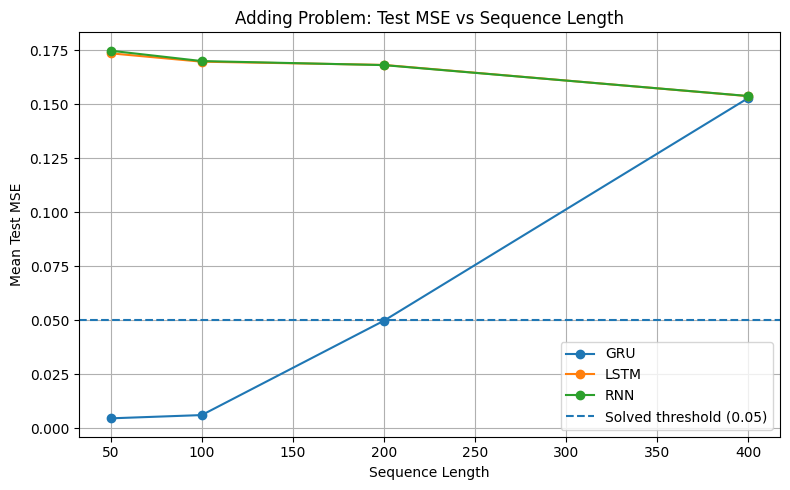

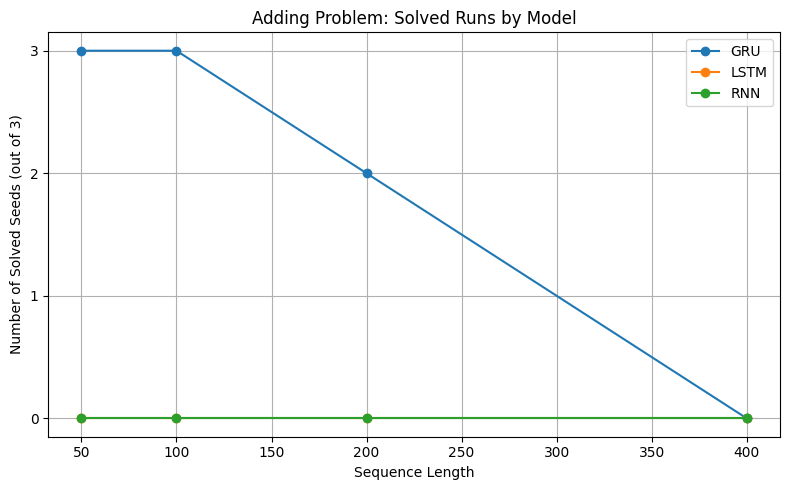

Summary and figures saved successfully.


In [17]:

# Step 7D: Summarize Adding Problem Results

import matplotlib.pyplot as plt
import pandas as pd

# Average test MSE and standard deviation across the three seeds
adding_summary = (
    adding_results_df
    .groupby(["model", "sequence_length"])
    .agg(
        mean_test_mse=("test_mse", "mean"),
        std_test_mse=("test_mse", "std"),
        solved_count=("solved", "sum"),
        mean_seconds_per_epoch=("seconds_per_epoch", "mean"),
        parameters=("parameters", "first")
    )
    .reset_index()
)

print("ADDING PROBLEM SUMMARY")
display(adding_summary.round(5))

# Save summary
adding_summary.to_csv(
    PROBLEM1_DIR / "adding_problem_summary.csv",
    index=False
)

# Plot 1: Mean test MSE versus sequence length
plt.figure(figsize=(8, 5))

for model_name in adding_summary["model"].unique():
    model_data = adding_summary[
        adding_summary["model"] == model_name
    ].sort_values("sequence_length")

    plt.plot(
        model_data["sequence_length"],
        model_data["mean_test_mse"],
        marker="o",
        label=model_name
    )

plt.axhline(0.05, linestyle="--", label="Solved threshold (0.05)")
plt.xlabel("Sequence Length")
plt.ylabel("Mean Test MSE")
plt.title("Adding Problem: Test MSE vs Sequence Length")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "adding_test_mse_vs_length.png",
    dpi=150
)
plt.show()

# Plot 2: Number of successful seeds
plt.figure(figsize=(8, 5))

for model_name in adding_summary["model"].unique():
    model_data = adding_summary[
        adding_summary["model"] == model_name
    ].sort_values("sequence_length")

    plt.plot(
        model_data["sequence_length"],
        model_data["solved_count"],
        marker="o",
        label=model_name
    )

plt.xlabel("Sequence Length")
plt.ylabel("Number of Solved Seeds (out of 3)")
plt.title("Adding Problem: Solved Runs by Model")
plt.yticks([0, 1, 2, 3])
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "adding_solved_counts.png",
    dpi=150
)
plt.show()

print("Summary and figures saved successfully.")


### Step 7E — Plot Learning Curves for the Adding Problem (T = 200)

RNN history type: dict
Available keys: ['train', 'validation']
LSTM history type: dict
Available keys: ['train', 'validation']
GRU history type: dict
Available keys: ['train', 'validation']


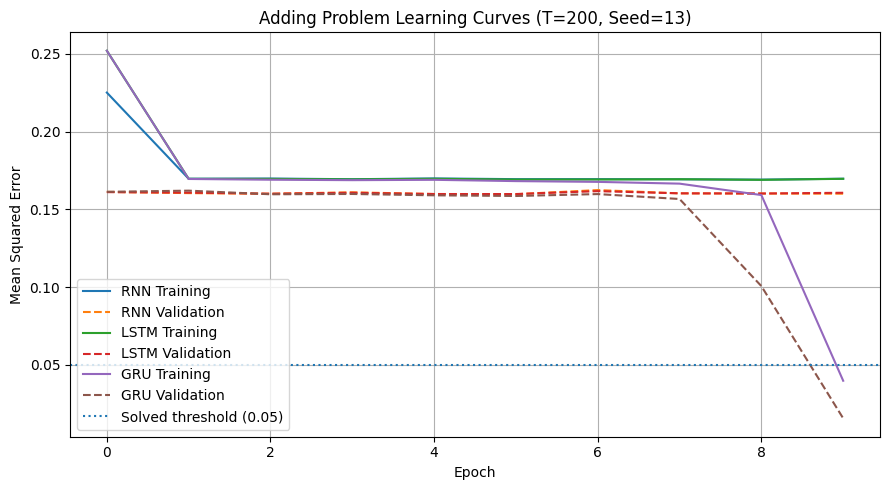

Learning curves saved successfully.


In [18]:
import matplotlib.pyplot as plt
import numpy as np

def get_loss_curves(history, model_name):
    print(f"{model_name} history type:", type(history).__name__)

    if isinstance(history, dict):
        print("Available keys:", list(history.keys()))

        train_key = next(
            (k for k in history if "train" in k.lower() and
             isinstance(history[k], (list, tuple, np.ndarray))),
            None
        )
        val_key = next(
            (k for k in history if
             ("val" in k.lower() or "valid" in k.lower()) and
             isinstance(history[k], (list, tuple, np.ndarray))),
            None
        )

        if train_key is not None and val_key is not None:
            return history[train_key], history[val_key]

    # Handle a list of epoch-wise dictionaries
    if isinstance(history, (list, tuple)) and len(history) > 0:
        if isinstance(history[0], dict):
            keys = list(history[0].keys())
            print("Available epoch keys:", keys)

            train_key = next(
                (k for k in keys if "train" in k.lower()), None
            )
            val_key = next(
                (k for k in keys
                 if "val" in k.lower() or "valid" in k.lower()),
                None
            )

            if train_key and val_key:
                return (
                    [item[train_key] for item in history],
                    [item[val_key] for item in history]
                )

    raise ValueError(
        f"Could not identify training and validation loss in "
        f"{model_name} history. Inspect the keys printed above."
    )


plt.figure(figsize=(9, 5))

for model_name in ["RNN", "LSTM", "GRU"]:
    history = adding_histories[(model_name, 13)]
    train_loss, val_loss = get_loss_curves(history, model_name)

    plt.plot(train_loss, label=f"{model_name} Training")
    plt.plot(val_loss, linestyle="--", label=f"{model_name} Validation")

plt.axhline(0.05, linestyle=":", label="Solved threshold (0.05)")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Adding Problem Learning Curves (T=200, Seed=13)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "adding_learning_curves_T200.png",
    dpi=150
)
plt.show()

print("Learning curves saved successfully.")


### Step 8 — Gradient Flow Analysis and Ablation Experiments

### Step 8A — Analyse Gradient Flow Through Time (T = 100)

Calculating gradients for RNN...
RNN: before shape = (100,), after shape = (100,)
Calculating gradients for LSTM...
LSTM: before shape = (100,), after shape = (100,)
Calculating gradients for GRU...
GRU: before shape = (100,), after shape = (100,)


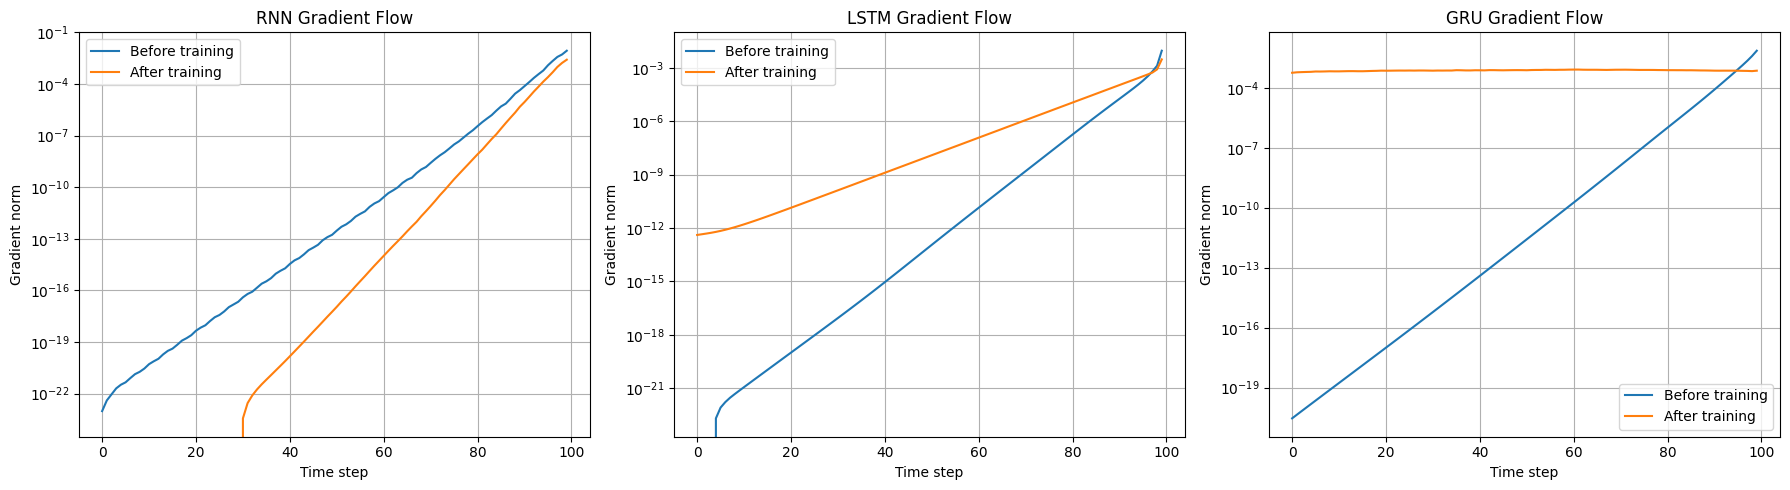

Step 8A completed. Gradient flow figure saved successfully.


In [19]:

def calculate_hidden_gradients(model, X, y):
    model.train()
    model.zero_grad(set_to_none=True)

    recurrent_layer = None
    classifier = None

    for module in model.modules():
        if isinstance(module, nn.RNNBase):
            recurrent_layer = module
        elif isinstance(module, nn.Linear):
            classifier = module

    if recurrent_layer is None or classifier is None:
        raise RuntimeError("Could not find recurrent layer or classifier.")

    batch_size, sequence_length, _ = X.shape

    captured_gradients = {}
    hidden_states = []

    # Disable cuDNN so gradients can be inspected at individual time steps.
    with torch.backends.cudnn.flags(enabled=False):

        h = torch.zeros(
            recurrent_layer.num_layers,
            batch_size,
            recurrent_layer.hidden_size,
            device=X.device
        )

        if isinstance(recurrent_layer, nn.LSTM):
            c = torch.zeros_like(h)

        for t in range(sequence_length):

            x_t = X[:, t:t+1, :]

            if isinstance(recurrent_layer, nn.LSTM):
                output, (h, c) = recurrent_layer(x_t, (h, c))
            else:
                output, h = recurrent_layer(x_t, h)

            # Store the hidden state and register a hook to capture its gradient.
            hidden_states.append(h)

            if h.requires_grad:
                h.register_hook(
                    lambda grad, step=t:
                        captured_gradients.__setitem__(
                            step, grad.detach().clone()
                        )
                )

        # Use the final hidden state to calculate the prediction.
        final_hidden = hidden_states[-1][-1]
        predictions = classifier(final_hidden)

        loss = nn.functional.mse_loss(
            predictions.squeeze(-1),
            y.squeeze(-1)
        )

        # One backward pass triggers the registered hooks.
        loss.backward()

    # Collect gradient norms in chronological order.
    gradient_norms = []

    for t in range(sequence_length):

        if t not in captured_gradients:
            raise RuntimeError(
                f"Gradient was not captured at time step {t}."
            )

        grad = captured_gradients[t]

        # Use the final recurrent layer.
        norm = grad[-1].norm(dim=1).mean().item()

        gradient_norms.append(norm)

    return np.array(gradient_norms)


# Prepare a batch from the T=100 adding dataset.
X_gradient = torch.tensor(
    adding_datasets[100]["X_train"][:128],
    dtype=torch.float32,
    device=DEVICE
)

y_gradient = torch.tensor(
    adding_datasets[100]["y_train"][:128],
    dtype=torch.float32,
    device=DEVICE
)

gradient_results = {}

for model_name in ["RNN", "LSTM", "GRU"]:

    print(f"Calculating gradients for {model_name}...")

    model = AddingModel(model_name).to(DEVICE)

    # Before training: randomly initialized model.
    before_norms = calculate_hidden_gradients(
        model, X_gradient, y_gradient
    )

    # Load the trained model checkpoint.
    checkpoint_path = (
        PROBLEM1_DIR
        / "adding_models"
        / f"{model_name.lower()}_T100_seed13.pt"
    )

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=DEVICE)
    )

    # After training.
    after_norms = calculate_hidden_gradients(
        model, X_gradient, y_gradient
    )

    gradient_results[model_name] = {
        "before": before_norms,
        "after": after_norms
    }

    print(
        f"{model_name}: before shape = {before_norms.shape}, "
        f"after shape = {after_norms.shape}"
    )


# Plot gradient norms for all three models.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, model_name in enumerate(["RNN", "LSTM", "GRU"]):

    axes[i].plot(
        gradient_results[model_name]["before"],
        label="Before training"
    )

    axes[i].plot(
        gradient_results[model_name]["after"],
        label="After training"
    )

    axes[i].set_yscale("log")
    axes[i].set_title(f"{model_name} Gradient Flow")
    axes[i].set_xlabel("Time step")
    axes[i].set_ylabel("Gradient norm")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "gradient_flow_T100.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Step 8A completed. Gradient flow figure saved successfully.")

### Step 8B — Hidden Size Ablation Study

Problem 1 folder: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1
Figures folder: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures

Model: LSTM | Hidden size: 16 | Seed: 13
Test accuracy: 0.8476 | Macro-F1: 0.8473 | Parameters: 1,830 | Seconds/epoch: 0.215

Model: LSTM | Hidden size: 16 | Seed: 309
Test accuracy: 0.8724 | Macro-F1: 0.8715 | Parameters: 1,830 | Seconds/epoch: 0.235

Model: LSTM | Hidden size: 16 | Seed: 2004
Test accuracy: 0.8700 | Macro-F1: 0.8695 | Parameters: 1,830 | Seconds/epoch: 0.211

Model: LSTM | Hidden size: 32 | Seed: 13
Test accuracy: 0.8877 | Macro-F1: 0.8881 | Parameters: 5,702 | Seconds/epoch: 0.230

Model: LSTM | Hidden size: 32 | Seed: 309
Test accuracy: 0.8884 | Macro-F1: 0.8882 | Parameters: 5,702 | Seconds/epoch: 0.225

Model: LSTM | Hidden size: 32 | Seed: 2004
Test accuracy: 0.8649 | Macro-F1: 0.8643 | Parameters: 5,702 | Seconds/epoch: 0.22

,model,hidden_size,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,seconds_per_epoch
0,GRU,16,0.8792,0.0126,0.8788,0.0126,1398,0.2145
1,GRU,32,0.8812,0.0181,0.8816,0.0183,4326,0.2079
2,GRU,64,0.8963,0.0087,0.8970,0.0093,14790,0.2162
3,GRU,128,0.9017,0.0211,0.9022,0.0215,54150,0.2101
4,LSTM,16,0.8634,0.0137,0.8627,0.0134,1830,0.2202
5,LSTM,32,0.8803,0.0133,0.8802,0.0138,5702,0.2264
6,LSTM,64,0.8949,0.0061,0.8952,0.0068,19590,0.2305
7,LSTM,128,0.9044,0.0110,0.9055,0.0120,71942,0.3234


Summary CSV saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/har_hidden_size_ablation_summary.csv


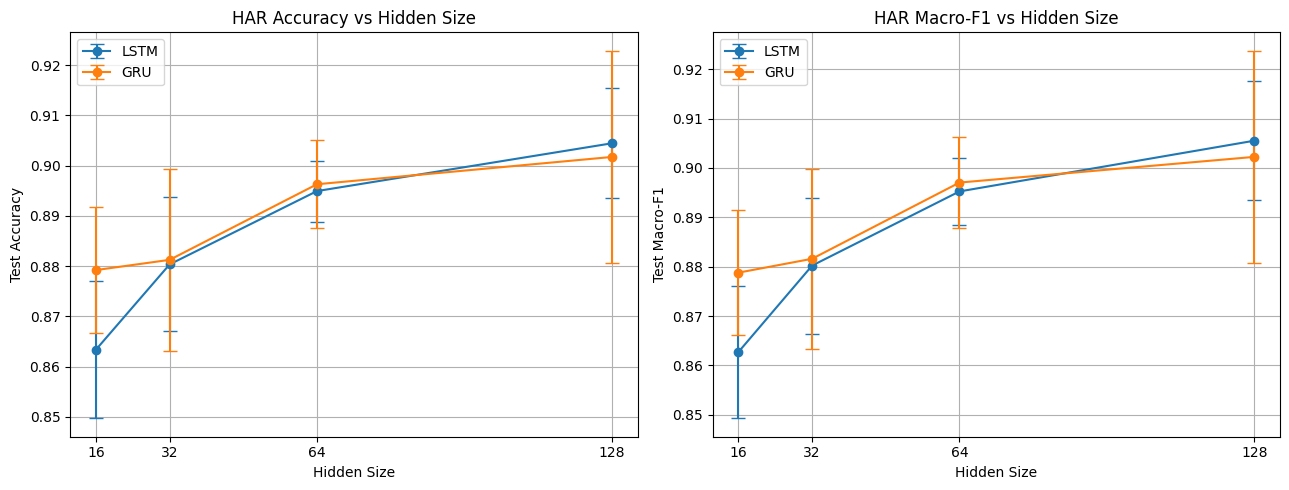


HAR HIDDEN-SIZE ABLATION COMPLETED SUCCESSFULLY
Total experiment runs: 24
Individual results CSV: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/har_hidden_size_ablation_results.csv
Summary CSV: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/har_hidden_size_ablation_summary.csv
Figure: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/har_hidden_size_ablation.png
All three output files exist and have been verified.


In [20]:

# Step 8B (Additional) — HAR Hidden-Size Ablation

import copy
import time
import random
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Set and create the correct output folders

PROJECT_ROOT = Path(
    "/content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer"
)

PROBLEM1_DIR = (
    PROJECT_ROOT
    / "2026AJ05309_DNN_Assignment2"
    / "problem1"
)

P1_FIGURES_DIR = PROBLEM1_DIR / "figures"

PROBLEM1_DIR.mkdir(parents=True, exist_ok=True)
P1_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Problem 1 folder:", PROBLEM1_DIR)
print("Figures folder:", P1_FIGURES_DIR)

# 2. Experiment configuration

HAR_HIDDEN_SIZES = [16, 32, 64, 128]
HAR_ABLATION_MODELS = ["LSTM", "GRU"]
HAR_ABLATION_SEEDS = [13, 309, 2004]

HAR_ABLATION_EPOCHS = EPOCHS
HAR_ABLATION_BATCH_SIZE = BATCH_SIZE
HAR_ABLATION_LR = LEARNING_RATE

# Start with a fresh result list

har_hidden_results = []

# 3. Run all 24 experiments

for model_name in HAR_ABLATION_MODELS:
    for hidden_size in HAR_HIDDEN_SIZES:
        for seed in HAR_ABLATION_SEEDS:

            print(
                f"\nModel: {model_name} | "
                f"Hidden size: {hidden_size} | Seed: {seed}"
            )

            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)

            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

            split = validation_splits[seed]

            X_train = torch.tensor(
                split["X_train_norm"],
                dtype=torch.float32,
                device=DEVICE
            )

            y_train = torch.tensor(
                split["y_train"] - 1,
                dtype=torch.long,
                device=DEVICE
            )

            X_val = torch.tensor(
                split["X_val_norm"],
                dtype=torch.float32,
                device=DEVICE
            )

            y_val = torch.tensor(
                split["y_val"] - 1,
                dtype=torch.long,
                device=DEVICE
            )

            X_test = torch.tensor(
                split["X_test_norm"],
                dtype=torch.float32,
                device=DEVICE
            )

            y_test = torch.tensor(
                y_test_original - 1,
                dtype=torch.long,
                device=DEVICE
            )

            model = HARSequenceClassifier(
                model_type=model_name,
                input_size=9,
                hidden_size=hidden_size,
                num_classes=6
            ).to(DEVICE)

            params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=HAR_ABLATION_LR
            )

            criterion = torch.nn.CrossEntropyLoss()

            best_val_f1 = -1.0
            best_state = None
            epoch_times = []

            for epoch in range(HAR_ABLATION_EPOCHS):

                model.train()
                start_time = time.perf_counter()

                permutation = torch.randperm(
                    len(X_train),
                    device=DEVICE
                )

                for start in range(
                    0,
                    len(permutation),
                    HAR_ABLATION_BATCH_SIZE
                ):

                    indices = permutation[
                        start:start + HAR_ABLATION_BATCH_SIZE
                    ]

                    batch_X = X_train[indices]
                    batch_y = y_train[indices]

                    optimizer.zero_grad()

                    logits = model(batch_X)
                    loss = criterion(logits, batch_y)

                    loss.backward()
                    optimizer.step()

                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()

                epoch_times.append(
                    time.perf_counter() - start_time
                )

                val_accuracy, val_f1 = evaluate_classifier(
                    model,
                    X_val,
                    y_val
                )

                if val_f1 > best_val_f1:
                    best_val_f1 = val_f1
                    best_state = copy.deepcopy(
                        model.state_dict()
                    )

            if best_state is None:
                raise RuntimeError(
                    f"No best model state saved for "
                    f"{model_name}, hidden size {hidden_size}, "
                    f"seed {seed}"
                )

            model.load_state_dict(best_state)

            test_accuracy, test_f1 = evaluate_classifier(
                model,
                X_test,
                y_test
            )

            har_hidden_results.append({
                "problem": "Problem 1 - HAR Hidden-size Ablation",
                "model": model_name,
                "hidden_size": hidden_size,
                "seed": seed,
                "test_accuracy": test_accuracy,
                "macro_f1": test_f1,
                "best_validation_macro_f1": best_val_f1,
                "parameters": params,
                "seconds_per_epoch": np.mean(epoch_times)
            })

            print(
                f"Test accuracy: {test_accuracy:.4f} | "
                f"Macro-F1: {test_f1:.4f} | "
                f"Parameters: {params:,} | "
                f"Seconds/epoch: {np.mean(epoch_times):.3f}"
            )

# 4. Create the results DataFrame

har_hidden_df = pd.DataFrame(har_hidden_results)

# 5. Save the individual experiment results CSV

har_hidden_csv = (
    PROBLEM1_DIR / "har_hidden_size_ablation_results.csv"
)

har_hidden_df.to_csv(
    har_hidden_csv,
    index=False
)

print("\nIndividual experiment CSV saved:", har_hidden_csv)

# 6. Verify the saved CSV by reading it again

har_hidden_check = pd.read_csv(har_hidden_csv)

assert len(har_hidden_check) == 24
assert set(har_hidden_check["model"]) == {"LSTM", "GRU"}
assert set(har_hidden_check["hidden_size"]) == {16, 32, 64, 128}
assert set(har_hidden_check["seed"]) == {13, 309, 2004}

assert har_hidden_check["test_accuracy"].notna().all()
assert har_hidden_check["macro_f1"].notna().all()
assert har_hidden_check["best_validation_macro_f1"].notna().all()

# Verify that every model-size-seed combination appears exactly once

assert not har_hidden_check.duplicated(
    ["model", "hidden_size", "seed"]
).any()

print("\nCSV VERIFICATION PASSED")
print("Verified experiment rows:", len(har_hidden_check))
print("Verified models:", sorted(har_hidden_check["model"].unique()))
print("Verified hidden sizes:", sorted(har_hidden_check["hidden_size"].unique()))
print("Verified seeds:", sorted(har_hidden_check["seed"].unique()))

# 7. Calculate the summary statistics

har_hidden_summary = (
    har_hidden_check
    .groupby(["model", "hidden_size"])
    .agg(
        accuracy_mean=("test_accuracy", "mean"),
        accuracy_std=("test_accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        parameters=("parameters", "first"),
        seconds_per_epoch=("seconds_per_epoch", "mean")
    )
    .reset_index()
)

print("\nHAR HIDDEN-SIZE ABLATION SUMMARY")
display(har_hidden_summary.round(4))

# 8. Save the summary CSV

har_hidden_summary_csv = (
    PROBLEM1_DIR / "har_hidden_size_ablation_summary.csv"
)

har_hidden_summary.to_csv(
    har_hidden_summary_csv,
    index=False
)

print("Summary CSV saved:", har_hidden_summary_csv)

# 9. Plot accuracy and macro-F1 against hidden size

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name in HAR_ABLATION_MODELS:

    data = har_hidden_summary[
        har_hidden_summary["model"] == model_name
    ].sort_values("hidden_size")

    axes[0].errorbar(
        data["hidden_size"],
        data["accuracy_mean"],
        yerr=data["accuracy_std"],
        marker="o",
        capsize=5,
        label=model_name
    )

    axes[1].errorbar(
        data["hidden_size"],
        data["macro_f1_mean"],
        yerr=data["macro_f1_std"],
        marker="o",
        capsize=5,
        label=model_name
    )

axes[0].set_title("HAR Accuracy vs Hidden Size")
axes[0].set_xlabel("Hidden Size")
axes[0].set_ylabel("Test Accuracy")

axes[1].set_title("HAR Macro-F1 vs Hidden Size")
axes[1].set_xlabel("Hidden Size")
axes[1].set_ylabel("Test Macro-F1")

for ax in axes:
    ax.set_xticks(HAR_HIDDEN_SIZES)
    ax.grid(True)
    ax.legend()

plt.tight_layout()

har_hidden_figure = (
    P1_FIGURES_DIR / "har_hidden_size_ablation.png"
)

plt.savefig(
    har_hidden_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# 10. Final output verification

assert har_hidden_csv.exists()
assert har_hidden_summary_csv.exists()
assert har_hidden_figure.exists()

assert len(pd.read_csv(har_hidden_csv)) == 24

print("\nHAR HIDDEN-SIZE ABLATION COMPLETED SUCCESSFULLY")
print("Total experiment runs:", len(har_hidden_check))
print("Individual results CSV:", har_hidden_csv)
print("Summary CSV:", har_hidden_summary_csv)
print("Figure:", har_hidden_figure)
print("All three output files exist and have been verified.")


Training LSTM | Hidden size=16 | Seed=13
Validation MSE: 0.159808 | Test MSE: 0.168294 | Parameters: 1297 | Seconds/epoch: 0.413

Training LSTM | Hidden size=16 | Seed=309
Validation MSE: 0.159924 | Test MSE: 0.168300 | Parameters: 1297 | Seconds/epoch: 0.353

Training LSTM | Hidden size=16 | Seed=2004
Validation MSE: 0.159774 | Test MSE: 0.168460 | Parameters: 1297 | Seconds/epoch: 0.346

Training LSTM | Hidden size=32 | Seed=13
Validation MSE: 0.159822 | Test MSE: 0.168827 | Parameters: 4641 | Seconds/epoch: 0.388

Training LSTM | Hidden size=32 | Seed=309
Validation MSE: 0.159822 | Test MSE: 0.168403 | Parameters: 4641 | Seconds/epoch: 0.374

Training LSTM | Hidden size=32 | Seed=2004
Validation MSE: 0.159720 | Test MSE: 0.168347 | Parameters: 4641 | Seconds/epoch: 0.342

Training LSTM | Hidden size=64 | Seed=13
Validation MSE: 0.159816 | Test MSE: 0.168387 | Parameters: 17473 | Seconds/epoch: 0.341

Training LSTM | Hidden size=64 | Seed=309
Validation MSE: 0.159825 | Test MSE: 0.1

,model,hidden_size,mean_test_mse,std_test_mse,parameters,mean_seconds_per_epoch
0,GRU,16,0.163454,0.004585,977.0,0.357473
1,GRU,32,0.138144,0.034638,3489.0,0.348225
2,GRU,64,0.049767,0.053393,13121.0,0.331594
3,GRU,128,0.011256,0.010903,50817.0,0.464626
4,LSTM,16,0.168352,0.000094,1297.0,0.370304
5,LSTM,32,0.168526,0.000263,4641.0,0.367918
6,LSTM,64,0.168285,0.000088,17473.0,0.364171
7,LSTM,128,0.168363,0.000122,67713.0,0.806216


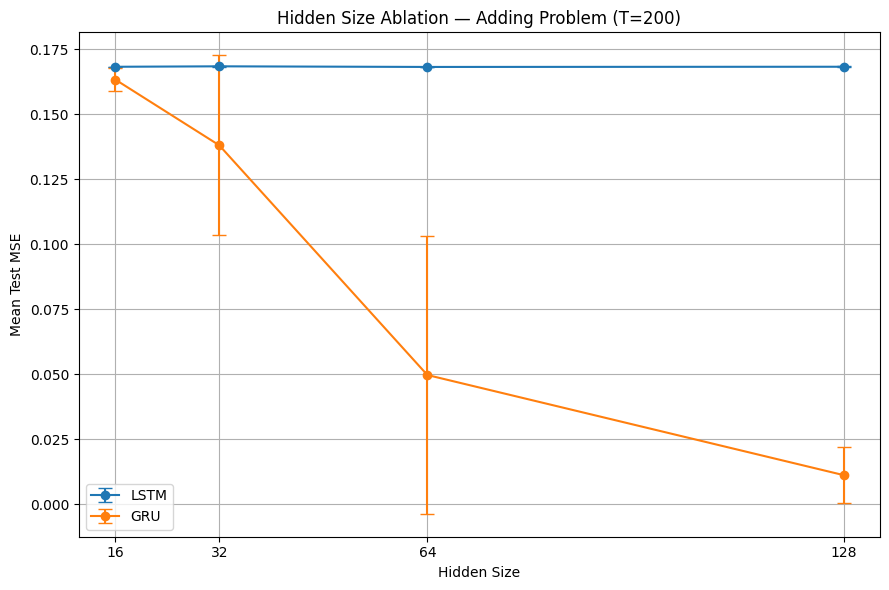


Step 8B completed.
Detailed results saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/hidden_size_ablation_results.csv
Figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/hidden_size_ablation.png


In [21]:
import time

HIDDEN_SIZES = [16, 32, 64, 128]
ABLATION_MODELS = ["LSTM", "GRU"]
ABLATION_SEEDS = [13, 309, 2004]

ABLATION_T = 200
ABLATION_EPOCHS = 10
ABLATION_BATCH_SIZE = 64
ABLATION_LR = 0.001

# Use the existing T=200 adding dataset.
X_train = torch.tensor(
    adding_datasets[ABLATION_T]["X_train"],
    dtype=torch.float32,
    device=DEVICE
)
y_train = torch.tensor(
    adding_datasets[ABLATION_T]["y_train"],
    dtype=torch.float32,
    device=DEVICE
).reshape(-1)

X_val = torch.tensor(
    adding_datasets[ABLATION_T]["X_val"],
    dtype=torch.float32,
    device=DEVICE
)
y_val = torch.tensor(
    adding_datasets[ABLATION_T]["y_val"],
    dtype=torch.float32,
    device=DEVICE
).reshape(-1)

X_test = torch.tensor(
    adding_datasets[ABLATION_T]["X_test"],
    dtype=torch.float32,
    device=DEVICE
)
y_test = torch.tensor(
    adding_datasets[ABLATION_T]["y_test"],
    dtype=torch.float32,
    device=DEVICE
).reshape(-1)


def evaluate_ablation_model(model, X, y):
    model.eval()

    with torch.no_grad():
        predictions = model(X)
        mse = nn.functional.mse_loss(
            predictions.reshape(-1),
            y.reshape(-1)
        ).item()

    return mse


# Folder for hidden-size ablation checkpoints.
ABLATION_DIR = PROBLEM1_DIR / "hidden_size_ablation"
ABLATION_DIR.mkdir(parents=True, exist_ok=True)

ablation_results = []

for model_name in ABLATION_MODELS:

    for hidden_size in HIDDEN_SIZES:

        for seed in ABLATION_SEEDS:

            print(
                f"\nTraining {model_name} | "
                f"Hidden size={hidden_size} | Seed={seed}"
            )

            # Reproducibility.
            np.random.seed(seed)
            torch.manual_seed(seed)

            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

            model = AddingModel(
                model_name,
                input_size=2,
                hidden_size=hidden_size
            ).to(DEVICE)

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=ABLATION_LR
            )

            loss_function = nn.MSELoss()

            parameter_count = sum(
                parameter.numel()
                for parameter in model.parameters()
                if parameter.requires_grad
            )

            best_validation_mse = float("inf")
            best_state = None
            epoch_times = []

            for epoch in range(ABLATION_EPOCHS):

                model.train()

                start_time = time.perf_counter()

                # Shuffle training samples.
                permutation = torch.randperm(
                    X_train.size(0),
                    device=DEVICE
                )

                for start in range(
                    0, X_train.size(0), ABLATION_BATCH_SIZE
                ):

                    indices = permutation[
                        start:start + ABLATION_BATCH_SIZE
                    ]

                    batch_X = X_train[indices]
                    batch_y = y_train[indices]

                    optimizer.zero_grad()

                    predictions = model(batch_X)

                    loss = loss_function(
                        predictions.reshape(-1),
                        batch_y
                    )

                    loss.backward()
                    optimizer.step()

                # Record epoch training time.
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()

                epoch_time = time.perf_counter() - start_time
                epoch_times.append(epoch_time)

                # Validation after every epoch.
                validation_mse = evaluate_ablation_model(
                    model, X_val, y_val
                )

                if validation_mse < best_validation_mse:

                    best_validation_mse = validation_mse

                    best_state = {
                        key: value.detach().cpu().clone()
                        for key, value in model.state_dict().items()
                    }

            # Restore the best validation checkpoint.
            model.load_state_dict(best_state)

            checkpoint_path = (
                ABLATION_DIR
                / f"{model_name.lower()}_H{hidden_size}_seed{seed}.pt"
            )

            torch.save(model.state_dict(), checkpoint_path)

            # Evaluate the selected model on the test set.
            test_mse = evaluate_ablation_model(
                model, X_test, y_test
            )

            average_epoch_time = float(np.mean(epoch_times))

            ablation_results.append({
                "model": model_name,
                "hidden_size": hidden_size,
                "seed": seed,
                "best_validation_mse": best_validation_mse,
                "test_mse": test_mse,
                "parameters": parameter_count,
                "seconds_per_epoch": average_epoch_time
            })

            print(
                f"Validation MSE: {best_validation_mse:.6f} | "
                f"Test MSE: {test_mse:.6f} | "
                f"Parameters: {parameter_count} | "
                f"Seconds/epoch: {average_epoch_time:.3f}"
            )


# Create detailed results table.
ablation_df = pd.DataFrame(ablation_results)

ablation_csv_path = (
    PROBLEM1_DIR / "hidden_size_ablation_results.csv"
)

ablation_df.to_csv(ablation_csv_path, index=False)


# Calculate mean and sample standard deviation across seeds.
ablation_summary = (
    ablation_df
    .groupby(["model", "hidden_size"])
    .agg(
        mean_test_mse=("test_mse", "mean"),
        std_test_mse=("test_mse", "std"),
        parameters=("parameters", "mean"),
        mean_seconds_per_epoch=("seconds_per_epoch", "mean")
    )
    .reset_index()
)

print("\nHIDDEN SIZE ABLATION SUMMARY")
display(ablation_summary.round(6))


# Plot test MSE against hidden size.
fig, ax = plt.subplots(figsize=(9, 6))

for model_name in ABLATION_MODELS:

    model_data = (
        ablation_summary[
            ablation_summary["model"] == model_name
        ].sort_values("hidden_size")
    )

    ax.errorbar(
        model_data["hidden_size"],
        model_data["mean_test_mse"],
        yerr=model_data["std_test_mse"],
        marker="o",
        capsize=5,
        label=model_name
    )

ax.set_xlabel("Hidden Size")
ax.set_ylabel("Mean Test MSE")
ax.set_title("Hidden Size Ablation — Adding Problem (T=200)")
ax.set_xticks(HIDDEN_SIZES)
ax.legend()
ax.grid(True)

plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "hidden_size_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nStep 8B completed.")
print("Detailed results saved:", ablation_csv_path)
print("Figure saved:", P1_FIGURES_DIR / "hidden_size_ablation.png")

#### My BITS registration number is 2026AJ05309. The last digit is 9, which is an odd number. According to the assignment instructions, students with **odd registration number endings** must perform the LSTM Forget Gate Bias Ablation (0 vs 1) experiment. Therefore, I have selected this experiment to analyse the **effect of forget gate bias initialization on LSTM performance**.

### Step 8C — LSTM Forget Gate Bias Ablation (0 vs 1)


Training LSTM | Forget bias=0.0 | Seed=13
Validation MSE: 0.159812 | Test MSE: 0.168383 | Parameters: 17473 | Seconds/epoch: 0.355

Training LSTM | Forget bias=0.0 | Seed=309
Validation MSE: 0.159831 | Test MSE: 0.168228 | Parameters: 17473 | Seconds/epoch: 0.342

Training LSTM | Forget bias=0.0 | Seed=2004
Validation MSE: 0.159785 | Test MSE: 0.168284 | Parameters: 17473 | Seconds/epoch: 0.347

Training LSTM | Forget bias=1.0 | Seed=13
Validation MSE: 0.159826 | Test MSE: 0.168277 | Parameters: 17473 | Seconds/epoch: 0.399

Training LSTM | Forget bias=1.0 | Seed=309
Validation MSE: 0.159746 | Test MSE: 0.168478 | Parameters: 17473 | Seconds/epoch: 0.347

Training LSTM | Forget bias=1.0 | Seed=2004
Validation MSE: 0.159788 | Test MSE: 0.168384 | Parameters: 17473 | Seconds/epoch: 0.340

LSTM FORGET GATE BIAS ABLATION SUMMARY


,forget_gate_bias,mean_test_mse,std_test_mse,mean_validation_mse,parameters,mean_seconds_per_epoch
0,0.0,0.168298,0.000079,0.159809,17473.0,0.348020
1,1.0,0.168380,0.000101,0.159787,17473.0,0.361951


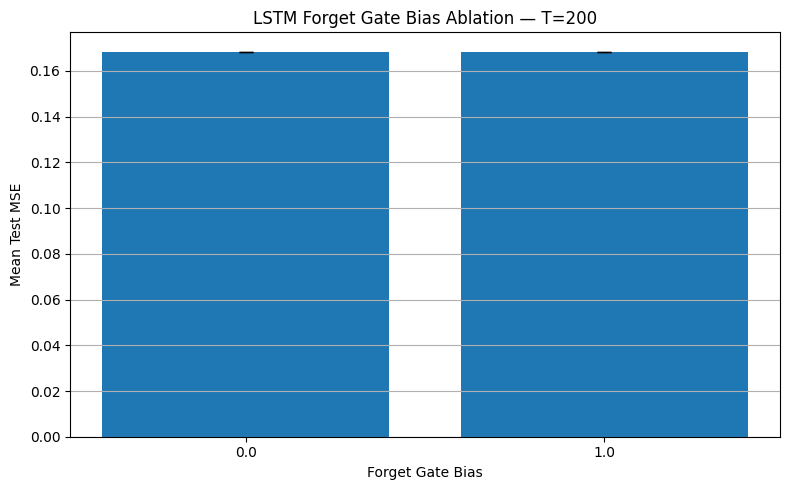


Step 8C completed.
Detailed results saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/forget_gate_ablation_results.csv
Figure saved: /content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer/2026AJ05309_DNN_Assignment2/problem1/figures/forget_gate_bias_ablation.png


In [22]:
FORGET_BIASES = [0.0, 1.0]
FORGET_SEEDS = [13, 309, 2004]

FORGET_T = 200
FORGET_EPOCHS = 10
FORGET_BATCH_SIZE = 64
FORGET_LR = 0.001

forget_results = []

FORGET_DIR = PROBLEM1_DIR / "forget_gate_ablation"
FORGET_DIR.mkdir(parents=True, exist_ok=True)


def set_lstm_forget_bias(model, forget_bias):
    """
    Set the effective LSTM forget gate bias to the requested value.

    PyTorch LSTM gate order: input, forget, cell, output.
    Effective bias = bias_ih + bias_hh.
    """

    lstm_layer = None

    for module in model.modules():
        if isinstance(module, nn.LSTM):
            lstm_layer = module
            break

    if lstm_layer is None:
        raise RuntimeError("LSTM layer not found in the model.")

    hidden_size = lstm_layer.hidden_size

    with torch.no_grad():

        # Set both forget-gate bias slices to zero first.
        lstm_layer.bias_ih_l0[
            hidden_size:2 * hidden_size
        ].zero_()

        lstm_layer.bias_hh_l0[
            hidden_size:2 * hidden_size
        ].zero_()

        # Set the requested effective forget bias in one vector.
        lstm_layer.bias_ih_l0[
            hidden_size:2 * hidden_size
        ].fill_(forget_bias)

    effective_bias = (
        lstm_layer.bias_ih_l0[hidden_size:2 * hidden_size]
        + lstm_layer.bias_hh_l0[hidden_size:2 * hidden_size]
    )

    if not torch.allclose(
        effective_bias,
        torch.full_like(effective_bias, forget_bias)
    ):
        raise RuntimeError("Forget gate bias verification failed.")


for forget_bias in FORGET_BIASES:

    for seed in FORGET_SEEDS:

        print(
            f"\nTraining LSTM | Forget bias={forget_bias} | Seed={seed}"
        )

        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        # Create LSTM model with the standard hidden size of 64.
        model = AddingModel(
            "LSTM",
            input_size=2,
            hidden_size=64
        ).to(DEVICE)

        # Apply the requested forget gate bias.
        set_lstm_forget_bias(model, forget_bias)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=FORGET_LR
        )

        loss_function = nn.MSELoss()

        parameter_count = sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )

        best_validation_mse = float("inf")
        best_state = None
        epoch_times = []

        for epoch in range(FORGET_EPOCHS):

            model.train()

            start_time = time.perf_counter()

            permutation = torch.randperm(
                X_train.size(0),
                device=DEVICE
            )

            for start in range(
                0, X_train.size(0), FORGET_BATCH_SIZE
            ):

                indices = permutation[
                    start:start + FORGET_BATCH_SIZE
                ]

                batch_X = X_train[indices]
                batch_y = y_train[indices]

                optimizer.zero_grad()

                predictions = model(batch_X)

                loss = loss_function(
                    predictions.reshape(-1),
                    batch_y
                )

                loss.backward()
                optimizer.step()

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            epoch_times.append(
                time.perf_counter() - start_time
            )

            validation_mse = evaluate_ablation_model(
                model, X_val, y_val
            )

            if validation_mse < best_validation_mse:

                best_validation_mse = validation_mse

                best_state = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }

        # Restore the best validation checkpoint.
        model.load_state_dict(best_state)

        checkpoint_path = (
            FORGET_DIR
            / f"lstm_forget_bias_{forget_bias}_seed_{seed}.pt"
        )

        torch.save(model.state_dict(), checkpoint_path)

        test_mse = evaluate_ablation_model(
            model, X_test, y_test
        )

        average_epoch_time = float(np.mean(epoch_times))

        forget_results.append({
            "model": "LSTM",
            "forget_gate_bias": forget_bias,
            "seed": seed,
            "best_validation_mse": best_validation_mse,
            "test_mse": test_mse,
            "parameters": parameter_count,
            "seconds_per_epoch": average_epoch_time
        })

        print(
            f"Validation MSE: {best_validation_mse:.6f} | "
            f"Test MSE: {test_mse:.6f} | "
            f"Parameters: {parameter_count} | "
            f"Seconds/epoch: {average_epoch_time:.3f}"
        )


# Save detailed experiment results.
forget_df = pd.DataFrame(forget_results)

forget_csv_path = (
    PROBLEM1_DIR / "forget_gate_ablation_results.csv"
)

forget_df.to_csv(forget_csv_path, index=False)


# Calculate mean and sample standard deviation across seeds.
forget_summary = (
    forget_df
    .groupby("forget_gate_bias")
    .agg(
        mean_test_mse=("test_mse", "mean"),
        std_test_mse=("test_mse", "std"),
        mean_validation_mse=("best_validation_mse", "mean"),
        parameters=("parameters", "mean"),
        mean_seconds_per_epoch=("seconds_per_epoch", "mean")
    )
    .reset_index()
)

print("\nLSTM FORGET GATE BIAS ABLATION SUMMARY")
display(forget_summary.round(6))


# Plot the comparison.
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    forget_summary["forget_gate_bias"].astype(str),
    forget_summary["mean_test_mse"],
    yerr=forget_summary["std_test_mse"],
    capsize=5
)

ax.set_xlabel("Forget Gate Bias")
ax.set_ylabel("Mean Test MSE")
ax.set_title("LSTM Forget Gate Bias Ablation — T=200")
ax.grid(axis="y")

plt.tight_layout()

plt.savefig(
    P1_FIGURES_DIR / "forget_gate_bias_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nStep 8C completed.")
print("Detailed results saved:", forget_csv_path)
print(
    "Figure saved:",
    P1_FIGURES_DIR / "forget_gate_bias_ablation.png"
)

**Step 8C — Results and Observations**

- Compared two configurations: **forget gate bias = 0** and **forget gate bias = 1**.
- Each configuration was tested using **three random seeds**.
- Mean test MSE:
  - **Bias 0:** 0.168298
  - **Bias 1:** 0.168380
- Both configurations **failed to solve the adding problem**, as their test MSE exceeded the required threshold of **0.05**.
- **Bias 0 performed slightly better**, but the difference was very small.
- Both configurations had the same number of **17,473 trainable parameters**.
- **Conclusion:** Changing the forget gate bias from 0 to 1 did not produce a meaningful improvement in LSTM performance in this experiment.

## Step 9 — Comparative Analysis and Final Observations

### 1. HAR Classification — Model Comparison

- **GRU achieved the highest mean test accuracy (89.63%) and macro-F1 (89.70%)** among the three models.
- LSTM performed very closely, with **89.49% accuracy and 89.52% macro-F1**.
- RNN achieved lower performance, with **78.53% accuracy and 78.30% macro-F1**.
- GRU used **14,790 parameters**, fewer than LSTM's 19,590 parameters.
- GRU also had a lower average training time per epoch than LSTM.
- **Overall, GRU provided the best balance of performance, model size and training time.**

### 2. Adding Problem — Effect of Sequence Length

- The adding problem became more challenging as the sequence length increased.
- **GRU performed best** among the three models.
- GRU solved all three runs at T=50 and T=100.
- At T=200, GRU solved **2 out of 3 runs**.
- At T=400, none of the GRU runs achieved the required MSE below 0.05.
- **RNN and LSTM failed to solve the task** at all four sequence lengths under the selected training settings.
- This shows that remembering information over longer sequences is challenging for recurrent networks.

### 3. Gradient Flow Analysis

- The RNN showed **vanishing gradients**, especially at earlier time steps.
- LSTM and GRU use gating mechanisms to control information flow.
- The gradient plots showed differences in gradient propagation before and after training.
- These results help explain why gated recurrent models can handle long-term dependencies better than a basic RNN.

### 4. Hidden Size Ablation

- Increasing the hidden size did not significantly improve LSTM performance in the selected 10-epoch experiments.
- GRU performance improved as the hidden size increased.
- **GRU with hidden size 128 achieved the lowest mean test MSE of 0.011256** and solved all three runs.
- However, its parameter count increased to **50,817**, compared with 977 parameters for GRU with hidden size 16.
- Larger hidden sizes can improve learning capacity but also increase computational cost.

### 5. LSTM Forget Gate Bias Ablation

- Compared forget gate bias values of **0 and 1** using three random seeds.
- Bias 0 achieved a mean test MSE of **0.168298**, while bias 1 achieved **0.168380**.
- Both configurations failed to solve the adding problem.
- **No meaningful performance improvement** was observed by changing the forget gate bias.

### 6. Recommendation for Wearable Activity Recognition

- **GRU is recommended** for wearable activity recognition based on these experiments.
- It achieved the highest mean HAR macro-F1 while using fewer parameters than LSTM.
- Its lower computational cost makes it a practical choice for resource-constrained wearable devices.
- LSTM is also a good alternative because its classification performance was very close to GRU.
- A basic RNN is less suitable here because it achieved lower classification performance.

### 7. Overall Conclusion

The experiments demonstrate that recurrent architectures differ in their ability to learn temporal patterns. **GRU provided the strongest overall results** in HAR classification and the adding problem under the selected experimental settings. Sequence length, hidden size and gate initialization all influenced model performance. These experiments highlight the importance of balancing prediction performance, model complexity and computational efficiency.

In [23]:

import subprocess
from pathlib import Path

REPO_DIR = Path(
    "/content/2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer"
)

GIT_USER_NAME = "Priyasahaana"
GIT_USER_EMAIL = "2026aj05309@wilp.bits-pilani.ac.in"

def run_git(command):
    result = subprocess.run(
        ["git"] + command,
        cwd=REPO_DIR,
        capture_output=True,
        text=True
    )
    return result

print("=" * 65)
print("GITHUB COMMIT AND PUSH")
print("=" * 65)

if not REPO_DIR.exists():
    print("ERROR: Repository directory does not exist.")
else:
    check_repo = run_git(["rev-parse", "--is-inside-work-tree"])

    if check_repo.returncode != 0:
        print("ERROR: The directory is not a Git repository.")
    else:
        remote = run_git(["remote", "get-url", "origin"])

        if remote.returncode != 0:
            print("ERROR: GitHub remote 'origin' is not configured.")
        else:
            branch_result = run_git(
                ["branch", "--show-current"]
            )
            branch = branch_result.stdout.strip()

            if not branch:
                print("ERROR: Could not identify the current branch.")
            else:
                print("Repository:", REPO_DIR.name)
                print("Branch:", branch)
                print("Remote: origin")

                run_git([
                    "config", "user.name", GIT_USER_NAME
                ])
                run_git([
                    "config", "user.email", GIT_USER_EMAIL
                ])

                print("\nSTEP 1: Checking file changes")

                status_before = run_git(["status", "--short"])
                print(status_before.stdout or "No uncommitted changes.")

                add_result = run_git(["add", "-A"])

                if add_result.returncode != 0:
                    print("ERROR while staging files:")
                    print(add_result.stderr)
                else:
                    staged = run_git([
                        "diff", "--cached", "--quiet"
                    ])

                    if staged.returncode == 0:
                        print("No new changes to commit.")
                    elif staged.returncode == 1:
                        print("\nSTEP 2: Creating commit")

                        commit_result = run_git([
                            "commit",
                            "-m",
                            "Update assignment results and project files"
                        ])

                        if commit_result.returncode == 0:
                            print(commit_result.stdout)
                        else:
                            print("Commit could not be completed:")
                            print(commit_result.stderr)
                    else:
                        print("Could not inspect staged changes:")
                        print(staged.stderr)

                print("\nSTEP 3: Checking GitHub remote")

                fetch_result = run_git([
                    "fetch", "origin"
                ])

                if fetch_result.returncode != 0:
                    print("Could not fetch remote updates:")
                    print(fetch_result.stderr)
                    print("Push skipped.")
                else:
                    upstream = run_git([
                        "rev-parse",
                        "--abbrev-ref",
                        "--symbolic-full-name",
                        "@{u}"
                    ])

                    if upstream.returncode != 0:
                        print("No upstream branch configured.")

                        push_result = run_git([
                            "push", "-u", "origin", branch
                        ])

                    else:
                        counts = run_git([
                            "rev-list",
                            "--left-right",
                            "--count",
                            f"HEAD...{upstream.stdout.strip()}"
                        ])

                        if counts.returncode != 0:
                            print("Could not compare local and remote commits.")
                            push_result = None
                        else:
                            ahead, behind = map(
                                int, counts.stdout.split()
                            )

                            print("Local commits to push:", ahead)
                            print("Remote commits not in local branch:", behind)

                            if behind > 0:
                                print(
                                    "\nRemote has newer commits. "
                                    "Attempting safe rebase."
                                )

                                pull_result = run_git([
                                    "pull",
                                    "--rebase",
                                    "--autostash",
                                    "origin",
                                    branch
                                ])

                                if pull_result.returncode != 0:
                                    print("Rebase could not be completed.")
                                    print(pull_result.stderr)
                                    print(
                                        "Resolve the Git conflict before "
                                        "running this cell again."
                                    )
                                    push_result = None
                                else:
                                    print(pull_result.stdout)
                                    push_result = run_git([
                                        "push", "origin", branch
                                    ])

                            elif ahead > 0:
                                print("\nSTEP 4: Pushing changes")
                                push_result = run_git([
                                    "push", "origin", branch
                                ])

                            else:
                                print(
                                    "\nGitHub is already up to date. "
                                    "Nothing to push."
                                )
                                push_result = None

                    if push_result is not None:
                        if push_result.returncode == 0:
                            print(push_result.stdout or "Push completed.")
                            print("GitHub synchronization successful.")
                        else:
                            print("Push could not be completed:")
                            print(push_result.stderr)
                            print(
                                "Check authentication, remote status "
                                "or repository permissions."
                            )

                print("\nSTEP 5: Final repository status")

                final_status = run_git(["status", "--short"])
                print(final_status.stdout or "Working tree is clean.")

                print("\nGITHUB OPERATION FINISHED")


GITHUB COMMIT AND PUSH
Repository: 2026AJ05309_DNN_Assignment2_RNN_LSTM_GRU_Transformer
Branch: main
Remote: origin

STEP 1: Checking file changes
 M 2026AJ05309_DNN_Assignment2/problem1/adding_problem_results.csv
 M 2026AJ05309_DNN_Assignment2/problem1/adding_problem_summary.csv
 M 2026AJ05309_DNN_Assignment2/problem1/figures/gradient_flow_T100.png
 M 2026AJ05309_DNN_Assignment2/problem1/forget_gate_ablation_results.csv
 M 2026AJ05309_DNN_Assignment2/problem1/har_classification_results.csv
 M 2026AJ05309_DNN_Assignment2/problem1/hidden_size_ablation_results.csv
?? 2026AJ05309_DNN_Assignment2/problem1/figures/har_hidden_size_ablation.png
?? 2026AJ05309_DNN_Assignment2/problem1/har_hidden_size_ablation_results.csv
?? 2026AJ05309_DNN_Assignment2/problem1/har_hidden_size_ablation_summary.csv


STEP 2: Creating commit
[main 8009175] Update assignment results and project files
 9 files changed, 121 insertions(+), 87 deletions(-)
 create mode 100644 2026AJ05309_DNN_Assignment2/problem1/figur